# 02. Data Warehouse: Star Schema Design and OLAP Analytics

**Stage 2 of the pipeline: model the cleaned transactions dimensionally and serve analytical queries from DuckDB.**

| | |
|---|---|
| **Project** | Online Retail II: Data Warehouse and Data Mining |
| **Author** | Sara Mohammad Zreigat |
| **Dataset** | UCI Online Retail II (cleaned), December 2009 to December 2011 |

### Objectives

1. Design a star schema at invoice-line grain with surrogate keys and conformed dimensions.
2. Build every dimension and the fact table, and verify referential integrity.
3. Create the physical warehouse in DuckDB from version-controlled DDL (the DDL and index scripts).
4. Answer core business questions with SQL  and benchmark them.

## 1. Environment setup

Put this notebook and **Online_Retail_II_Cleaned.csv** in the same folder (or, on Google Colab, run the cells and upload
the CSV when asked). The first code cell installs the two libraries Colab may be missing, the second holds the project's
helper functions, and the third loads the data.

In [ ]:
%pip install -q mlxtend duckdb

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

In [3]:
# @title Project helper library (run this cell first)
# All reusable functions of the project in one place so this notebook runs on its own.
# Author: Sara Mohammad Zreigat

from types import SimpleNamespace
import logging


# ============================================================================
# Module: config
# ============================================================================

"""Project-wide configuration: paths, constants and analysis parameters."""


from pathlib import Path

# ---------------------------------------------------------------------------
# Paths
# ---------------------------------------------------------------------------
PROJECT_ROOT = Path.cwd()

DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

PROCESSED_DATASET = PROJECT_ROOT / "Online_Retail_II_Cleaned.csv"
RAW_DATASET = RAW_DATA_DIR / "online_retail_II.xlsx"

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
WAREHOUSE_DIR = ARTIFACTS_DIR / "warehouse"
WAREHOUSE_DB = WAREHOUSE_DIR / "retail_dw.duckdb"
FIGURES_DIR = PROJECT_ROOT / "figures"
SQL_DIR = PROJECT_ROOT / "sql"

# ---------------------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------------------
RANDOM_STATE = 42

# ---------------------------------------------------------------------------
# Domain constants
# ---------------------------------------------------------------------------
# Stock codes that represent fees, postage, adjustments or test entries rather
# than merchandise. They are kept in revenue totals but excluded from
# product-level analysis (rankings, market basket analysis).
NON_MERCHANDISE_CODES: frozenset[str] = frozenset(
    {
        "POST",
        "DOT",
        "M",
        "C2",
        "ADJUST",
        "ADJUST2",
        "BANK CHARGES",
        "PADS",
        "D",
        "TEST001",
        "TEST002",
        "AMAZONFEE",
        "CRUK",
        "S",
        "B",
    }
)

RAW_SHEETS: tuple[str, ...] = ("Year 2009-2010", "Year 2010-2011")

RAW_COLUMN_MAP: dict[str, str] = {
    "Invoice": "InvoiceNo",
    "Price": "UnitPrice",
    "Customer ID": "CustomerID",
}

CLEAN_COLUMNS: list[str] = [
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "DateKey",
    "Year",
    "Month",
    "Day",
    "Quarter",
    "Hour",
    "UnitPrice",
    "TotalAmount",
    "CustomerID",
    "Country",
]

# ---------------------------------------------------------------------------
# Analysis parameters
# ---------------------------------------------------------------------------
BASKET_COUNTRY = "United Kingdom"
APRIORI_MIN_SUPPORT = 0.01
RULES_MIN_CONFIDENCE = 0.30
RULES_MIN_LIFT = 1.0

KMEANS_K_RANGE = range(2, 9)
KMEANS_MIN_K = 3  # smallest number of segments that is actionable for marketing

TEST_MONTH_SHARE = 0.20

# ---------------------------------------------------------------------------
# Visual identity (shared by notebooks and dashboard)
# ---------------------------------------------------------------------------
PALETTE = {
    "primary": "#1F3A5F",
    "secondary": "#3D7EA6",
    "accent": "#C8963E",
    "positive": "#2E8B57",
    "negative": "#B23A48",
    "neutral": "#8A94A6",
    "background": "#F6F8FB",
    "ink": "#1B2430",
}

SEGMENT_COLORS = {
    "Champions": "#1F3A5F",
    "Promising": "#3D7EA6",
    "At Risk": "#C8963E",
    "Hibernating": "#8A94A6",
}

CATEGORICAL_SEQUENCE = [
    "#1F3A5F",
    "#3D7EA6",
    "#C8963E",
    "#2E8B57",
    "#B23A48",
    "#6C5B7B",
    "#8A94A6",
]


def ensure_directories() -> None:
    """Create all output directories used by the pipeline."""
    for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, WAREHOUSE_DIR, FIGURES_DIR):
        directory.mkdir(parents=True, exist_ok=True)

config = SimpleNamespace(PROJECT_ROOT=PROJECT_ROOT, DATA_DIR=DATA_DIR, RAW_DATA_DIR=RAW_DATA_DIR, PROCESSED_DATA_DIR=PROCESSED_DATA_DIR, PROCESSED_DATASET=PROCESSED_DATASET, RAW_DATASET=RAW_DATASET, ARTIFACTS_DIR=ARTIFACTS_DIR, WAREHOUSE_DIR=WAREHOUSE_DIR, WAREHOUSE_DB=WAREHOUSE_DB, FIGURES_DIR=FIGURES_DIR, SQL_DIR=SQL_DIR, RANDOM_STATE=RANDOM_STATE, NON_MERCHANDISE_CODES=NON_MERCHANDISE_CODES, RAW_SHEETS=RAW_SHEETS, RAW_COLUMN_MAP=RAW_COLUMN_MAP, CLEAN_COLUMNS=CLEAN_COLUMNS, BASKET_COUNTRY=BASKET_COUNTRY, APRIORI_MIN_SUPPORT=APRIORI_MIN_SUPPORT, RULES_MIN_CONFIDENCE=RULES_MIN_CONFIDENCE, RULES_MIN_LIFT=RULES_MIN_LIFT, KMEANS_K_RANGE=KMEANS_K_RANGE, KMEANS_MIN_K=KMEANS_MIN_K, TEST_MONTH_SHARE=TEST_MONTH_SHARE, PALETTE=PALETTE, SEGMENT_COLORS=SEGMENT_COLORS, CATEGORICAL_SEQUENCE=CATEGORICAL_SEQUENCE, ensure_directories=ensure_directories)


# ============================================================================
# Module: data
# ============================================================================

"""Data access, cleaning (ETL) and data-quality validation.

The repository ships the cleaned transactional dataset in
``data/processed/online_retail_ii_cleaned.parquet``. The full cleaning logic
that produced it from the raw UCI workbook is implemented in
:func:`clean_raw_transactions` so that the processed file can be regenerated
from source at any time (see ``scripts/run_pipeline.py --from-raw``).
"""


from pathlib import Path

import numpy as np
import pandas as pd


# ---------------------------------------------------------------------------
# Loading
# ---------------------------------------------------------------------------

_DTYPES = {
    "InvoiceNo": "string",
    "StockCode": "string",
    "Description": "string",
    "Country": "string",
}


def _standardise_types(df: pd.DataFrame) -> pd.DataFrame:
    """Apply the canonical dtypes used throughout the project."""
    df = df.copy()
    for column, dtype in _DTYPES.items():
        if column in df.columns:
            df[column] = df[column].astype(dtype)
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
    df["CustomerID"] = df["CustomerID"].astype("int64")
    for column in ("Quantity", "DateKey", "Year", "Month", "Day", "Quarter", "Hour"):
        if column in df.columns:
            df[column] = df[column].astype("int64")
    for column in ("UnitPrice", "TotalAmount"):
        df[column] = df[column].astype("float64")
    return df


def load_transactions(path: str | Path | None = None) -> pd.DataFrame:
    """Load the cleaned transaction-level dataset.

    Parameters
    ----------
    path:
        Optional path to a ``.parquet`` or ``.csv`` file. Defaults to the
        processed dataset shipped with the repository.
    """
    path = Path(path) if path is not None else config.PROCESSED_DATASET
    if not path.exists():
        raise FileNotFoundError(
            f"Dataset not found at '{path}'. Make sure the repository data "
            "folder is present or run scripts/run_pipeline.py --from-raw."
        )
    if path.suffix == ".parquet":
        df = pd.read_parquet(path)
    else:
        df = pd.read_csv(path, dtype={k: "string" for k in _DTYPES})
    df = _standardise_types(df)
    return df[config.CLEAN_COLUMNS].sort_values(["InvoiceDate", "InvoiceNo"]).reset_index(drop=True)


def load_raw_workbook(path: str | Path | None = None) -> pd.DataFrame:
    """Read and concatenate both yearly sheets of the raw UCI workbook."""
    path = Path(path) if path is not None else config.RAW_DATASET
    if not path.exists():
        raise FileNotFoundError(
            f"Raw workbook not found at '{path}'. Download 'online_retail_II.xlsx' "
            "from https://archive.ics.uci.edu/dataset/502/online+retail+ii "
            "and place it in data/raw/."
        )
    frames = [pd.read_excel(path, sheet_name=sheet) for sheet in config.RAW_SHEETS]
    return pd.concat(frames, ignore_index=True)


# ---------------------------------------------------------------------------
# Cleaning (ETL transform step)
# ---------------------------------------------------------------------------


def add_time_features(df: pd.DataFrame) -> pd.DataFrame:
    """Derive calendar attributes used by the time dimension."""
    df = df.copy()
    dates = df["InvoiceDate"]
    df["DateKey"] = dates.dt.strftime("%Y%m%d").astype("int64")
    df["Year"] = dates.dt.year.astype("int64")
    df["Month"] = dates.dt.month.astype("int64")
    df["Day"] = dates.dt.day.astype("int64")
    df["Quarter"] = dates.dt.quarter.astype("int64")
    df["Hour"] = dates.dt.hour.astype("int64")
    return df


def clean_raw_transactions(raw: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply the full cleaning procedure to raw Online Retail II records.

    Steps
    -----
    1. Standardise column names.
    2. Trim text fields and parse invoice timestamps.
    3. Drop records without a customer identifier or product description.
    4. Remove exact duplicate rows.
    5. Remove cancelled invoices (invoice numbers prefixed with ``C``).
    6. Keep only positive quantities and positive unit prices.
    7. Derive calendar features and the ``TotalAmount`` measure.

    Returns
    -------
    clean:
        The cleaned dataset with the canonical column order.
    audit:
        A step-by-step log of the number of rows removed by each rule.
    """
    log: list[dict[str, object]] = []

    def record(step: str, before: int, after: int) -> None:
        log.append({"Step": step, "RowsBefore": before, "RowsAfter": after, "RowsRemoved": before - after})

    df = raw.rename(columns=config.RAW_COLUMN_MAP).copy()
    record("Input records", len(df), len(df))

    df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()
    df["StockCode"] = df["StockCode"].astype("string").str.strip().str.upper()
    df["Description"] = df["Description"].astype("string").str.strip()
    df["Country"] = df["Country"].astype("string").str.strip()
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

    before = len(df)
    df = df.dropna(subset=["CustomerID"])
    record("Drop missing CustomerID", before, len(df))

    before = len(df)
    df = df.dropna(subset=["Description"])
    df = df[df["Description"].str.len() > 0]
    record("Drop missing Description", before, len(df))

    before = len(df)
    df = df.drop_duplicates()
    record("Remove exact duplicates", before, len(df))

    before = len(df)
    df = df[~df["InvoiceNo"].str.startswith("C")]
    record("Remove cancelled invoices", before, len(df))

    before = len(df)
    df = df[df["Quantity"] > 0]
    record("Keep Quantity > 0", before, len(df))

    before = len(df)
    df = df[df["UnitPrice"] > 0]
    record("Keep UnitPrice > 0", before, len(df))

    before = len(df)
    df = df.dropna(subset=["InvoiceDate"])
    record("Drop invalid dates", before, len(df))

    df = add_time_features(df)
    df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]
    df = _standardise_types(df)
    df = df[config.CLEAN_COLUMNS].sort_values(["InvoiceDate", "InvoiceNo"]).reset_index(drop=True)

    return df, pd.DataFrame(log)


# ---------------------------------------------------------------------------
# Validation
# ---------------------------------------------------------------------------


def validate_transactions(df: pd.DataFrame) -> pd.DataFrame:
    """Run data-quality assertions and return a tabular report.

    Every rule enforced by :func:`clean_raw_transactions` is re-checked here,
    together with internal consistency checks on derived columns.
    """
    expected_total = df["Quantity"] * df["UnitPrice"]
    expected_datekey = df["InvoiceDate"].dt.strftime("%Y%m%d").astype("int64")

    checks = [
        ("Schema matches canonical column list", list(df.columns) == config.CLEAN_COLUMNS, 0),
        ("No missing values", True, int(df.isna().sum().sum())),
        ("No exact duplicate rows", True, int(df.duplicated().sum())),
        ("No cancelled invoices", True, int(df["InvoiceNo"].str.startswith("C").sum())),
        ("Quantity strictly positive", True, int((df["Quantity"] <= 0).sum())),
        ("UnitPrice strictly positive", True, int((df["UnitPrice"] <= 0).sum())),
        ("TotalAmount equals Quantity x UnitPrice", True, int((~np.isclose(df["TotalAmount"], expected_total, atol=0.01)).sum())),
        ("DateKey consistent with InvoiceDate", True, int((df["DateKey"] != expected_datekey).sum())),
        ("Year consistent with InvoiceDate", True, int((df["Year"] != df["InvoiceDate"].dt.year).sum())),
        ("Quarter consistent with Month", True, int((df["Quarter"] != (df["Month"] - 1) // 3 + 1).sum())),
    ]

    rows = []
    for name, structural_ok, violations in checks:
        passed = bool(structural_ok) and violations == 0
        rows.append({"Check": name, "Violations": violations, "Status": "PASS" if passed else "FAIL"})
    return pd.DataFrame(rows)


def dataset_profile(df: pd.DataFrame) -> pd.DataFrame:
    """High-level descriptive profile of the dataset."""
    metrics = {
        "Transaction lines": len(df),
        "Invoices": df["InvoiceNo"].nunique(),
        "Customers": df["CustomerID"].nunique(),
        "Products (stock codes)": df["StockCode"].nunique(),
        "Countries": df["Country"].nunique(),
        "First invoice": df["InvoiceDate"].min().strftime("%Y-%m-%d"),
        "Last invoice": df["InvoiceDate"].max().strftime("%Y-%m-%d"),
        "Total revenue (GBP)": f"{df['TotalAmount'].sum():,.2f}",
        "Total units sold": f"{df['Quantity'].sum():,}",
    }
    return pd.DataFrame({"Metric": list(metrics.keys()), "Value": [str(v) for v in metrics.values()]})


def merchandise_only(df: pd.DataFrame) -> pd.DataFrame:
    """Exclude fee, postage, adjustment and test stock codes."""
    return df[~df["StockCode"].isin(config.NON_MERCHANDISE_CODES)]

# ============================================================================
# Module: plotting
# ============================================================================

"""Consistent Matplotlib styling and figure export for notebooks and reports."""


from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


PALETTE = config.PALETTE


def set_style() -> None:
    """Apply the project-wide Matplotlib theme."""
    mpl.rcParams.update(
        {
            "figure.figsize": (10, 5.2),
            "figure.dpi": 110,
            "savefig.dpi": 160,
            "savefig.bbox": "tight",
            "figure.facecolor": "white",
            "axes.facecolor": "white",
            "axes.edgecolor": "#C9D1DC",
            "axes.linewidth": 0.8,
            "axes.grid": True,
            "axes.grid.axis": "y",
            "grid.color": "#E6EAF0",
            "grid.linewidth": 0.8,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "axes.titlesize": 13,
            "axes.titleweight": "bold",
            "axes.titlelocation": "left",
            "axes.titlepad": 12,
            "axes.labelsize": 10.5,
            "axes.labelcolor": PALETTE["ink"],
            "xtick.color": "#4A5568",
            "ytick.color": "#4A5568",
            "xtick.labelsize": 9.5,
            "ytick.labelsize": 9.5,
            "legend.frameon": False,
            "legend.fontsize": 9.5,
            "font.family": "DejaVu Sans",
            "axes.prop_cycle": mpl.cycler(color=config.CATEGORICAL_SEQUENCE),
        }
    )


def currency_formatter(prefix: str = "GBP ") -> FuncFormatter:
    """Compact currency tick labels (e.g. GBP 1.2M)."""

    def _fmt(value: float, _pos=None) -> str:
        magnitude = abs(value)
        if magnitude >= 1e6:
            return f"{prefix}{value / 1e6:.1f}M"
        if magnitude >= 1e3:
            return f"{prefix}{value / 1e3:.0f}K"
        return f"{prefix}{value:.0f}"

    return FuncFormatter(_fmt)


def thousands_formatter() -> FuncFormatter:
    return FuncFormatter(lambda value, _pos=None: f"{value / 1e3:.0f}K" if abs(value) >= 1e3 else f"{value:.0f}")


def save_figure(fig: plt.Figure, name: str, directory: Path | None = None) -> Path:
    """Save a figure as PNG into ``reports/figures``."""
    directory = directory or config.FIGURES_DIR
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / f"{name}.png"
    fig.savefig(path)
    return path


def star_schema_diagram(tables: dict[str, list[str]], keys: dict[str, dict[str, str]]) -> plt.Figure:
    """Draw an entity-relationship diagram of a star schema.

    Parameters
    ----------
    tables:
        Mapping of table name to its column list. The table whose name starts
        with ``fact`` is drawn in the centre.
    keys:
        Mapping of table name to ``{column: "PK" | "FK"}`` annotations.
    """
    from matplotlib.patches import FancyBboxPatch

    fact_name = next(name for name in tables if name.startswith("fact"))
    dims = [name for name in tables if name != fact_name]
    positions = {fact_name: (0.5, 0.5)}
    corners = [(0.14, 0.78), (0.86, 0.78), (0.14, 0.24), (0.86, 0.24)]
    for name, pos in zip(dims, corners):
        positions[name] = pos

    fig, ax = plt.subplots(figsize=(13, 8.2))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    row_h = 0.032
    width = 0.24
    boxes = {}
    for name, (cx, cy) in positions.items():
        columns = tables[name]
        height = row_h * (len(columns) + 1.4)
        x0, y0 = cx - width / 2, cy - height / 2
        is_fact = name == fact_name
        header_color = PALETTE["primary"] if is_fact else PALETTE["secondary"]
        ax.add_patch(FancyBboxPatch((x0, y0), width, height, boxstyle="round,pad=0.004,rounding_size=0.01",
                                    facecolor="white", edgecolor=header_color, linewidth=1.6, zorder=2))
        ax.add_patch(FancyBboxPatch((x0, y0 + height - row_h * 1.3), width, row_h * 1.3,
                                    boxstyle="round,pad=0.004,rounding_size=0.01", facecolor=header_color,
                                    edgecolor=header_color, linewidth=1.6, zorder=3))
        ax.text(cx, y0 + height - row_h * 0.65, name.upper(), ha="center", va="center", color="white",
                fontsize=10.5, fontweight="bold", zorder=4)
        for i, column in enumerate(columns):
            tag = keys.get(name, {}).get(column, "")
            y = y0 + height - row_h * (1.3 + i + 0.6)
            ax.text(x0 + 0.012, y, column, ha="left", va="center", fontsize=8.6, color=PALETTE["ink"], zorder=4,
                    fontweight="bold" if tag == "PK" else "normal")
            if tag:
                ax.text(x0 + width - 0.012, y, tag, ha="right", va="center", fontsize=7.6, zorder=4,
                        color=PALETTE["accent"] if tag == "PK" else PALETTE["secondary"])
        boxes[name] = (x0, y0, width, height)

    fx0, fy0, fw, fh = boxes[fact_name]
    for name in dims:
        x0, y0, w, h = boxes[name]
        cx, cy = positions[name]
        start_x = fx0 if cx < 0.5 else fx0 + fw
        end_x = x0 + w if cx < 0.5 else x0
        ax.annotate("", xy=(start_x, 0.5 + (0.08 if cy > 0.5 else -0.08)), xytext=(end_x, cy),
                    arrowprops=dict(arrowstyle="-|>", color=PALETTE["neutral"], linewidth=1.3,
                                    connectionstyle="arc3,rad=0.0"), zorder=1)
    ax.set_title("Star schema: one fact table at invoice-line grain, four conformed dimensions", loc="left")
    return fig


def pretty_label(text: str, width: int | None = None) -> str:
    """Title-case a product description without breaking apostrophes, optionally wrapping it."""
    import string
    import textwrap

    label = string.capwords(" ".join(str(text).lower().split()))
    return "\n".join(textwrap.wrap(label, width)) if width else label

# ============================================================================
# Module: artifacts
# ============================================================================

"""Locations and helpers for persisted pipeline outputs.

Small, version-controlled result tables live under ``artifacts/`` so that the
dashboard and the documentation can be rebuilt without re-running the models.
Large binaries (the DuckDB file and fitted models) are regenerated locally and
excluded from version control.
"""


import json
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd


QUALITY_DIR = config.ARTIFACTS_DIR / "quality"
WAREHOUSE_DIR = config.WAREHOUSE_DIR
SEGMENTATION_DIR = config.ARTIFACTS_DIR / "segmentation"
ASSOCIATION_DIR = config.ARTIFACTS_DIR / "association"
MODELING_DIR = config.ARTIFACTS_DIR / "modeling"
MODELS_DIR = config.ARTIFACTS_DIR / "models"

ALL_DIRS = (QUALITY_DIR, WAREHOUSE_DIR, SEGMENTATION_DIR, ASSOCIATION_DIR, MODELING_DIR, MODELS_DIR)


def ensure_dirs() -> None:
    config.ensure_directories()
    for directory in ALL_DIRS:
        directory.mkdir(parents=True, exist_ok=True)


class _Encoder(json.JSONEncoder):
    def default(self, obj: Any):  # noqa: D401 - JSON hook
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        if isinstance(obj, (np.integer,)):
            return int(obj)
        if isinstance(obj, (np.floating,)):
            return float(obj)
        return super().default(obj)


def save_table(frame: pd.DataFrame, path: Path) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.suffix == ".parquet":
        frame.to_parquet(path, index=False)
    else:
        frame.to_csv(path, index=False)
    return path


def load_table(path: Path) -> pd.DataFrame:
    return pd.read_parquet(path) if path.suffix == ".parquet" else pd.read_csv(path)


def save_json(payload: dict, path: Path) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2, cls=_Encoder), encoding="utf-8")
    return path


def load_json(path: Path) -> dict:
    return json.loads(Path(path).read_text(encoding="utf-8"))

# ============================================================================
# Module: warehouse
# ============================================================================

SQL_FILES = {
    "schema.sql": """-- =============================================================================
-- Online Retail II - Star Schema (DuckDB dialect, ANSI-compatible)
-- Grain of the fact table: one row per invoice line.
-- Author: Sara Mohammad Zreigat
-- =============================================================================

-- -----------------------------------------------------------------------------
-- Dimension: calendar date (day grain)
-- -----------------------------------------------------------------------------
CREATE TABLE dim_date (
    DateKey        INTEGER      PRIMARY KEY,   -- YYYYMMDD smart key
    FullDate       DATE         NOT NULL,
    Year           SMALLINT     NOT NULL,
    Quarter        TINYINT      NOT NULL,
    Month          TINYINT      NOT NULL,
    MonthName      VARCHAR(12)  NOT NULL,
    YearMonth      VARCHAR(7)   NOT NULL,
    Day            TINYINT      NOT NULL,
    DayOfWeek      TINYINT      NOT NULL,      -- 1 = Monday ... 7 = Sunday
    DayName        VARCHAR(10)  NOT NULL,
    WeekOfYear     TINYINT      NOT NULL,
    IsWeekend      BOOLEAN      NOT NULL
);

-- -----------------------------------------------------------------------------
-- Dimension: customer
-- -----------------------------------------------------------------------------
CREATE TABLE dim_customer (
    CustomerKey        INTEGER      PRIMARY KEY,   -- surrogate key
    CustomerID         INTEGER      NOT NULL UNIQUE, -- natural key from source
    PrimaryCountry     VARCHAR(40)  NOT NULL,
    FirstPurchaseDate  DATE         NOT NULL,
    LastPurchaseDate   DATE         NOT NULL
);

-- -----------------------------------------------------------------------------
-- Dimension: product
-- -----------------------------------------------------------------------------
CREATE TABLE dim_product (
    ProductKey          INTEGER        PRIMARY KEY,  -- surrogate key
    StockCode           VARCHAR(20)    NOT NULL UNIQUE,
    Description         VARCHAR(100)   NOT NULL,
    ReferenceUnitPrice  DECIMAL(10, 2) NOT NULL,
    IsMerchandise       BOOLEAN        NOT NULL
);

-- -----------------------------------------------------------------------------
-- Dimension: location
-- -----------------------------------------------------------------------------
CREATE TABLE dim_location (
    LocationKey   INTEGER      PRIMARY KEY,      -- surrogate key
    Country       VARCHAR(40)  NOT NULL UNIQUE,  -- value as recorded in source
    CountryName   VARCHAR(40)  NOT NULL,         -- standardised display name
    ISO3          VARCHAR(3),
    Region        VARCHAR(30)  NOT NULL
);

-- -----------------------------------------------------------------------------
-- Fact: sales (invoice line grain)
-- -----------------------------------------------------------------------------
CREATE TABLE fact_sales (
    SalesKey      BIGINT          PRIMARY KEY,
    InvoiceNo     VARCHAR(10)     NOT NULL,      -- degenerate dimension
    DateKey       INTEGER         NOT NULL REFERENCES dim_date (DateKey),
    CustomerKey   INTEGER         NOT NULL REFERENCES dim_customer (CustomerKey),
    ProductKey    INTEGER         NOT NULL REFERENCES dim_product (ProductKey),
    LocationKey   INTEGER         NOT NULL REFERENCES dim_location (LocationKey),
    InvoiceHour   TINYINT         NOT NULL,
    Quantity      INTEGER         NOT NULL CHECK (Quantity > 0),
    UnitPrice     DECIMAL(10, 3)  NOT NULL CHECK (UnitPrice > 0),
    TotalAmount   DECIMAL(14, 3)  NOT NULL
);
""",
    "indexes.sql": """-- =============================================================================
-- Secondary indexes on fact foreign keys and frequently filtered attributes.
-- DuckDB uses ART indexes for point lookups and highly selective filters;
-- large aggregations rely on its columnar storage and zone maps.
-- =============================================================================

CREATE INDEX idx_fact_sales_date      ON fact_sales (DateKey);
CREATE INDEX idx_fact_sales_customer  ON fact_sales (CustomerKey);
CREATE INDEX idx_fact_sales_product   ON fact_sales (ProductKey);
CREATE INDEX idx_fact_sales_location  ON fact_sales (LocationKey);
CREATE INDEX idx_fact_sales_invoice   ON fact_sales (InvoiceNo);

CREATE INDEX idx_dim_date_year_month  ON dim_date (Year, Month);
CREATE INDEX idx_dim_location_region  ON dim_location (Region);
""",
    "analytical_queries.sql": """-- =============================================================================
-- Analytical (OLAP) queries against the Online Retail II star schema.
-- Each query is delimited by a "-- name:" tag so it can be loaded
-- programmatically (see retail_analytics.warehouse.load_named_queries).
-- =============================================================================

-- name: revenue_by_country
-- Revenue, volume and order metrics by country and region.
SELECT
    l.CountryName                              AS Country,
    l.Region,
    COUNT(DISTINCT f.InvoiceNo)                AS Orders,
    COUNT(DISTINCT f.CustomerKey)              AS Customers,
    CAST(SUM(f.Quantity) AS BIGINT)            AS UnitsSold,
    ROUND(SUM(f.TotalAmount), 2)               AS Revenue,
    ROUND(SUM(f.TotalAmount) / COUNT(DISTINCT f.InvoiceNo), 2) AS AvgOrderValue,
    ROUND(100.0 * SUM(f.TotalAmount) / SUM(SUM(f.TotalAmount)) OVER (), 2) AS RevenueSharePct
FROM fact_sales f
JOIN dim_location l ON f.LocationKey = l.LocationKey
GROUP BY l.CountryName, l.Region
ORDER BY Revenue DESC;

-- name: monthly_sales_trend
-- Monthly revenue with month-over-month and year-over-year growth.
WITH monthly AS (
    SELECT
        d.Year,
        d.Month,
        d.YearMonth,
        COUNT(DISTINCT f.InvoiceNo)   AS Orders,
        COUNT(DISTINCT f.CustomerKey) AS ActiveCustomers,
        SUM(f.TotalAmount)            AS Revenue
    FROM fact_sales f
    JOIN dim_date d ON f.DateKey = d.DateKey
    GROUP BY d.Year, d.Month, d.YearMonth
)
SELECT
    YearMonth,
    Year,
    Month,
    Orders,
    ActiveCustomers,
    ROUND(Revenue, 2) AS Revenue,
    ROUND(100.0 * (Revenue / LAG(Revenue) OVER (ORDER BY Year, Month) - 1), 2)  AS MoMGrowthPct,
    ROUND(100.0 * (Revenue / LAG(Revenue, 12) OVER (ORDER BY Year, Month) - 1), 2) AS YoYGrowthPct
FROM monthly
ORDER BY Year, Month;

-- name: top_products_by_revenue
-- Ten highest-revenue merchandise products.
SELECT
    p.StockCode,
    p.Description,
    CAST(SUM(f.Quantity) AS BIGINT)      AS UnitsSold,
    COUNT(DISTINCT f.InvoiceNo)          AS Orders,
    ROUND(SUM(f.TotalAmount), 2)         AS Revenue,
    ROUND(SUM(f.TotalAmount) / SUM(f.Quantity), 2) AS AvgSellingPrice
FROM fact_sales f
JOIN dim_product p ON f.ProductKey = p.ProductKey
WHERE p.IsMerchandise
GROUP BY p.StockCode, p.Description
ORDER BY Revenue DESC
LIMIT 10;

-- name: repeat_customer_value
-- Customers with more than five orders, ranked by lifetime revenue.
SELECT
    c.CustomerID,
    c.PrimaryCountry,
    COUNT(DISTINCT f.InvoiceNo)                AS Orders,
    CAST(SUM(f.Quantity) AS BIGINT)            AS UnitsPurchased,
    ROUND(SUM(f.TotalAmount), 2)               AS LifetimeRevenue,
    ROUND(SUM(f.TotalAmount) / COUNT(DISTINCT f.InvoiceNo), 2) AS AvgOrderValue,
    c.FirstPurchaseDate,
    c.LastPurchaseDate
FROM fact_sales f
JOIN dim_customer c ON f.CustomerKey = c.CustomerKey
GROUP BY c.CustomerID, c.PrimaryCountry, c.FirstPurchaseDate, c.LastPurchaseDate
HAVING COUNT(DISTINCT f.InvoiceNo) > 5
ORDER BY LifetimeRevenue DESC;

-- name: sales_by_weekday_hour
-- Order activity heat map by weekday and hour of day.
SELECT
    d.DayOfWeek,
    d.DayName,
    f.InvoiceHour                  AS Hour,
    COUNT(DISTINCT f.InvoiceNo)    AS Orders,
    ROUND(SUM(f.TotalAmount), 2)   AS Revenue
FROM fact_sales f
JOIN dim_date d ON f.DateKey = d.DateKey
GROUP BY d.DayOfWeek, d.DayName, f.InvoiceHour
ORDER BY d.DayOfWeek, Hour;

-- name: quarterly_rollup
-- ROLLUP across year and quarter with subtotals and a grand total.
SELECT
    COALESCE(CAST(d.Year AS VARCHAR), 'All years')        AS Year,
    COALESCE(CAST(d.Quarter AS VARCHAR), 'All quarters') AS Quarter,
    COUNT(DISTINCT f.InvoiceNo)                           AS Orders,
    ROUND(SUM(f.TotalAmount), 2)                          AS Revenue
FROM fact_sales f
JOIN dim_date d ON f.DateKey = d.DateKey
GROUP BY ROLLUP (d.Year, d.Quarter)
ORDER BY d.Year NULLS LAST, d.Quarter NULLS LAST;

-- name: customer_cohort_retention
-- Share of each monthly acquisition cohort that purchased again N months later.
WITH first_purchase AS (
    SELECT CustomerKey, MIN(DateKey) AS FirstDateKey
    FROM fact_sales
    GROUP BY CustomerKey
),
activity AS (
    SELECT DISTINCT
        f.CustomerKey,
        fd.Year * 12 + fd.Month AS CohortIndex,
        d.Year * 12 + d.Month   AS ActivityIndex,
        fd.YearMonth            AS Cohort
    FROM fact_sales f
    JOIN first_purchase fp ON f.CustomerKey = fp.CustomerKey
    JOIN dim_date d  ON f.DateKey = d.DateKey
    JOIN dim_date fd ON fp.FirstDateKey = fd.DateKey
)
SELECT
    Cohort,
    ActivityIndex - CohortIndex AS MonthsSinceFirstPurchase,
    COUNT(DISTINCT CustomerKey) AS ActiveCustomers
FROM activity
GROUP BY Cohort, ActivityIndex - CohortIndex
ORDER BY Cohort, MonthsSinceFirstPurchase;
""",
}

"""Dimensional modelling: star schema construction and DuckDB warehouse."""


import time
from pathlib import Path

import duckdb
import pandas as pd


# Country metadata: display name, ISO-3166 alpha-3 code and sales region.
COUNTRY_METADATA: dict[str, tuple[str, str | None, str]] = {
    "United Kingdom": ("United Kingdom", "GBR", "United Kingdom"),
    "Channel Islands": ("Channel Islands", None, "United Kingdom"),
    "EIRE": ("Ireland", "IRL", "Western Europe"),
    "Germany": ("Germany", "DEU", "Western Europe"),
    "France": ("France", "FRA", "Western Europe"),
    "Netherlands": ("Netherlands", "NLD", "Western Europe"),
    "Belgium": ("Belgium", "BEL", "Western Europe"),
    "Switzerland": ("Switzerland", "CHE", "Western Europe"),
    "Austria": ("Austria", "AUT", "Western Europe"),
    "Spain": ("Spain", "ESP", "Southern Europe"),
    "Portugal": ("Portugal", "PRT", "Southern Europe"),
    "Italy": ("Italy", "ITA", "Southern Europe"),
    "Greece": ("Greece", "GRC", "Southern Europe"),
    "Cyprus": ("Cyprus", "CYP", "Southern Europe"),
    "Malta": ("Malta", "MLT", "Southern Europe"),
    "Sweden": ("Sweden", "SWE", "Northern Europe"),
    "Norway": ("Norway", "NOR", "Northern Europe"),
    "Finland": ("Finland", "FIN", "Northern Europe"),
    "Denmark": ("Denmark", "DNK", "Northern Europe"),
    "Iceland": ("Iceland", "ISL", "Northern Europe"),
    "Lithuania": ("Lithuania", "LTU", "Northern Europe"),
    "Poland": ("Poland", "POL", "Eastern Europe"),
    "Czech Republic": ("Czech Republic", "CZE", "Eastern Europe"),
    "European Community": ("European Community", None, "Western Europe"),
    "USA": ("United States", "USA", "Americas"),
    "Canada": ("Canada", "CAN", "Americas"),
    "Brazil": ("Brazil", "BRA", "Americas"),
    "West Indies": ("West Indies", None, "Americas"),
    "Australia": ("Australia", "AUS", "Asia Pacific"),
    "Japan": ("Japan", "JPN", "Asia Pacific"),
    "Singapore": ("Singapore", "SGP", "Asia Pacific"),
    "Korea": ("South Korea", "KOR", "Asia Pacific"),
    "Thailand": ("Thailand", "THA", "Asia Pacific"),
    "United Arab Emirates": ("United Arab Emirates", "ARE", "Middle East & Africa"),
    "Israel": ("Israel", "ISR", "Middle East & Africa"),
    "Bahrain": ("Bahrain", "BHR", "Middle East & Africa"),
    "Lebanon": ("Lebanon", "LBN", "Middle East & Africa"),
    "Saudi Arabia": ("Saudi Arabia", "SAU", "Middle East & Africa"),
    "RSA": ("South Africa", "ZAF", "Middle East & Africa"),
    "Nigeria": ("Nigeria", "NGA", "Middle East & Africa"),
    "Unspecified": ("Unspecified", None, "Unspecified"),
}

TABLE_LOAD_ORDER = ("dim_date", "dim_customer", "dim_product", "dim_location", "fact_sales")


def _mode(series: pd.Series):
    counts = series.value_counts()
    return counts.index[0] if len(counts) else None


def build_dim_date(df: pd.DataFrame) -> pd.DataFrame:
    """Calendar dimension at day grain covering the full transaction period."""
    calendar = pd.date_range(df["InvoiceDate"].min().normalize(), df["InvoiceDate"].max().normalize(), freq="D")
    dim = pd.DataFrame({"FullDate": calendar})
    dim["DateKey"] = dim["FullDate"].dt.strftime("%Y%m%d").astype("int64")
    dim["Year"] = dim["FullDate"].dt.year
    dim["Quarter"] = dim["FullDate"].dt.quarter
    dim["Month"] = dim["FullDate"].dt.month
    dim["MonthName"] = dim["FullDate"].dt.month_name()
    dim["YearMonth"] = dim["FullDate"].dt.strftime("%Y-%m")
    dim["Day"] = dim["FullDate"].dt.day
    dim["DayOfWeek"] = dim["FullDate"].dt.dayofweek + 1
    dim["DayName"] = dim["FullDate"].dt.day_name()
    dim["WeekOfYear"] = dim["FullDate"].dt.isocalendar().week.astype("int64")
    dim["IsWeekend"] = dim["DayOfWeek"] >= 6
    dim["FullDate"] = dim["FullDate"].dt.date
    return dim[
        ["DateKey", "FullDate", "Year", "Quarter", "Month", "MonthName", "YearMonth",
         "Day", "DayOfWeek", "DayName", "WeekOfYear", "IsWeekend"]
    ]


def build_dim_customer(df: pd.DataFrame) -> pd.DataFrame:
    """Customer dimension with a surrogate key and the customer's primary country."""
    grouped = df.groupby("CustomerID")
    dim = pd.DataFrame(
        {
            "PrimaryCountry": grouped["Country"].agg(_mode),
            "FirstPurchaseDate": grouped["InvoiceDate"].min().dt.date,
            "LastPurchaseDate": grouped["InvoiceDate"].max().dt.date,
        }
    ).reset_index()
    dim = dim.sort_values("CustomerID").reset_index(drop=True)
    dim.insert(0, "CustomerKey", range(1, len(dim) + 1))
    return dim


def build_dim_product(df: pd.DataFrame) -> pd.DataFrame:
    """Product dimension keyed by stock code with a canonical description."""
    grouped = df.groupby("StockCode")
    dim = pd.DataFrame(
        {
            "Description": grouped["Description"].agg(_mode),
            "ReferenceUnitPrice": grouped["UnitPrice"].median().round(2),
        }
    ).reset_index()
    dim["IsMerchandise"] = ~dim["StockCode"].isin(config.NON_MERCHANDISE_CODES)
    dim = dim.sort_values("StockCode").reset_index(drop=True)
    dim.insert(0, "ProductKey", range(1, len(dim) + 1))
    return dim


def build_dim_location(df: pd.DataFrame) -> pd.DataFrame:
    """Geographic dimension with ISO codes and sales regions."""
    countries = sorted(df["Country"].unique())
    rows = []
    for key, country in enumerate(countries, start=1):
        display, iso3, region = COUNTRY_METADATA.get(country, (country, None, "Other"))
        rows.append(
            {"LocationKey": key, "Country": country, "CountryName": display, "ISO3": iso3, "Region": region}
        )
    return pd.DataFrame(rows)


def build_fact_sales(
    df: pd.DataFrame,
    dim_customer: pd.DataFrame,
    dim_product: pd.DataFrame,
    dim_location: pd.DataFrame,
) -> pd.DataFrame:
    """Fact table at invoice-line grain with foreign keys to every dimension."""
    fact = df[["InvoiceNo", "DateKey", "Hour", "CustomerID", "StockCode", "Country",
               "Quantity", "UnitPrice", "TotalAmount"]].copy()
    fact = fact.merge(dim_customer[["CustomerKey", "CustomerID"]], on="CustomerID", how="left")
    fact = fact.merge(dim_product[["ProductKey", "StockCode"]], on="StockCode", how="left")
    fact = fact.merge(dim_location[["LocationKey", "Country"]], on="Country", how="left")
    fact = fact.rename(columns={"Hour": "InvoiceHour"})
    fact.insert(0, "SalesKey", range(1, len(fact) + 1))
    return fact[
        ["SalesKey", "InvoiceNo", "DateKey", "CustomerKey", "ProductKey", "LocationKey",
         "InvoiceHour", "Quantity", "UnitPrice", "TotalAmount"]
    ]


def build_star_schema(df: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Build every dimension and the fact table from the cleaned dataset."""
    dim_date = build_dim_date(df)
    dim_customer = build_dim_customer(df)
    dim_product = build_dim_product(df)
    dim_location = build_dim_location(df)
    fact_sales = build_fact_sales(df, dim_customer, dim_product, dim_location)
    return {
        "dim_date": dim_date,
        "dim_customer": dim_customer,
        "dim_product": dim_product,
        "dim_location": dim_location,
        "fact_sales": fact_sales,
    }


def schema_summary(schema: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Row and column counts for every warehouse table."""
    return pd.DataFrame(
        [
            {"Table": name, "Type": "Fact" if name.startswith("fact") else "Dimension",
             "Rows": len(frame), "Columns": frame.shape[1]}
            for name, frame in schema.items()
        ]
    )


def check_referential_integrity(schema: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Verify that every foreign key in the fact table resolves to a dimension row."""
    fact = schema["fact_sales"]
    relations = [
        ("DateKey", "dim_date"),
        ("CustomerKey", "dim_customer"),
        ("ProductKey", "dim_product"),
        ("LocationKey", "dim_location"),
    ]
    rows = []
    for key, table in relations:
        orphans = int((~fact[key].isin(schema[table][key])).sum()) + int(fact[key].isna().sum())
        rows.append({"ForeignKey": f"fact_sales.{key}", "References": f"{table}.{key}",
                     "OrphanRows": orphans, "Status": "PASS" if orphans == 0 else "FAIL"})
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# DuckDB
# ---------------------------------------------------------------------------


def _read_sql(name: str) -> str:
    return SQL_FILES[name]


def split_sql_statements(sql_text: str) -> list[str]:
    """Split a SQL script into statements, dropping comment-only fragments."""
    statements = []
    for chunk in sql_text.split(";"):
        lines = [line for line in chunk.splitlines() if not line.strip().startswith("--")]
        statement = "\n".join(lines).strip()
        if statement:
            statements.append(statement)
    return statements


def load_named_queries(file_name: str = "analytical_queries.sql") -> dict[str, str]:
    """Parse ``-- name: <query_name>`` blocks from a SQL file."""
    queries: dict[str, str] = {}
    current_name: str | None = None
    buffer: list[str] = []
    for line in _read_sql(file_name).splitlines():
        stripped = line.strip()
        if stripped.lower().startswith("-- name:"):
            if current_name:
                queries[current_name] = "\n".join(buffer).strip().rstrip(";")
            current_name = stripped.split(":", 1)[1].strip()
            buffer = []
        elif current_name is not None:
            buffer.append(line)
    if current_name:
        queries[current_name] = "\n".join(buffer).strip().rstrip(";")
    return queries


def create_warehouse(schema: dict[str, pd.DataFrame], db_path: str | Path | None = None) -> duckdb.DuckDBPyConnection:
    """Create the DuckDB warehouse from ``sql/schema.sql`` and load all tables.

    Passing ``db_path=":memory:"`` builds an in-memory warehouse.
    """
    target = str(db_path) if db_path is not None else str(config.WAREHOUSE_DB)
    if target != ":memory:":
        Path(target).parent.mkdir(parents=True, exist_ok=True)
        Path(target).unlink(missing_ok=True)
    con = duckdb.connect(target)

    for statement in split_sql_statements(_read_sql("schema.sql")):
        con.execute(statement)

    for table in TABLE_LOAD_ORDER:
        frame = schema[table]
        con.register("staging_frame", frame)
        columns = ", ".join(frame.columns)
        con.execute(f"INSERT INTO {table} ({columns}) SELECT {columns} FROM staging_frame")
        con.unregister("staging_frame")

    for statement in split_sql_statements(_read_sql("indexes.sql")):
        con.execute(statement)
    return con


def run_query(con: duckdb.DuckDBPyConnection, sql: str) -> tuple[pd.DataFrame, float]:
    """Execute a query and return the result with its execution time in ms."""
    start = time.perf_counter()
    result = con.execute(sql).df()
    elapsed_ms = (time.perf_counter() - start) * 1000
    return result, elapsed_ms

# ============================================================================
# Module: association
# ============================================================================

"""Market basket analysis with the Apriori algorithm."""


import re

import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules



def product_catalogue(df: pd.DataFrame) -> pd.Series:
    """Canonical (most frequent) description for every stock code."""
    return df.groupby("StockCode")["Description"].agg(lambda s: s.value_counts().index[0])


def build_basket(df: pd.DataFrame, country: str | None = config.BASKET_COUNTRY) -> pd.DataFrame:
    """One-hot invoice x product matrix for merchandise lines.

    Products are keyed by stock code (several codes carry slightly different
    descriptions over time) and labelled with their canonical description.
    """
    lines = merchandise_only(df)
    if country is not None:
        lines = lines[lines["Country"] == country]
    names = product_catalogue(lines)
    basket = pd.crosstab(lines["InvoiceNo"], lines["StockCode"]).gt(0)
    basket.columns = [f"{names[code]} [{code}]" for code in basket.columns]
    return basket


def mine_frequent_itemsets(basket: pd.DataFrame, min_support: float = config.APRIORI_MIN_SUPPORT) -> pd.DataFrame:
    """Run Apriori and return itemsets sorted by support."""
    itemsets = apriori(basket, min_support=min_support, use_colnames=True, low_memory=True)
    itemsets["Length"] = itemsets["itemsets"].apply(len)
    return itemsets.sort_values("support", ascending=False).reset_index(drop=True)


def generate_rules(
    itemsets: pd.DataFrame,
    min_confidence: float = config.RULES_MIN_CONFIDENCE,
    min_lift: float = config.RULES_MIN_LIFT,
) -> pd.DataFrame:
    """Derive association rules filtered by confidence and lift."""
    rules = association_rules(itemsets, metric="confidence", min_threshold=min_confidence)
    rules = rules[rules["lift"] > min_lift]
    return rules.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)


def _format_itemset(items) -> str:
    return " + ".join(sorted(items))


def readable_rules(rules: pd.DataFrame) -> pd.DataFrame:
    """Flatten frozensets into strings and keep the key interestingness metrics."""
    table = pd.DataFrame(
        {
            "Antecedent": rules["antecedents"].apply(_format_itemset),
            "Consequent": rules["consequents"].apply(_format_itemset),
            "Support": rules["support"].round(4),
            "Confidence": rules["confidence"].round(4),
            "Lift": rules["lift"].round(2),
            "Leverage": rules["leverage"].round(4),
            "Conviction": rules["conviction"].round(2),
        }
    )
    return table


def readable_itemsets(itemsets: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "Itemset": itemsets["itemsets"].apply(_format_itemset),
            "Items": itemsets["Length"],
            "Support": itemsets["support"].round(4),
        }
    )


def strip_codes(text: str) -> str:
    """Remove the trailing '[STOCKCODE]' tags for presentation."""
    return re.sub(r"\s\[[^\]]+\]", "", text)


def recommendation_statements(rules_table: pd.DataFrame, top_n: int = 10) -> list[str]:
    """Translate the strongest unique rules into cross-selling statements."""
    seen: set[frozenset[str]] = set()
    statements = []
    for _, row in rules_table.iterrows():
        pair = frozenset({row["Antecedent"], row["Consequent"]})
        if pair in seen:
            continue
        seen.add(pair)
        statements.append(
            f"Customers who buy {strip_codes(row['Antecedent'])} also buy "
            f"{strip_codes(row['Consequent'])} in {row['Confidence']:.0%} of cases "
            f"(lift {row['Lift']:.1f}, support {row['Support']:.2%})."
        )
        if len(statements) == top_n:
            break
    return statements

# ============================================================================
# Module: segmentation
# ============================================================================

"""Customer segmentation with RFM features and K-Means clustering."""


import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


RFM_FEATURES = ["Recency", "Frequency", "Monetary"]

SEGMENT_PLAYBOOK = {
    "Champions": (
        "Recent, frequent and high-spending customers that generate the majority of revenue.",
        "Protect with VIP loyalty tiers, early access to new ranges, dedicated account management "
        "and volume-based pricing.",
    ),
    "Promising": (
        "Recently active customers with few orders so far; the main pipeline for future champions.",
        "Nurture with onboarding journeys, second-order incentives and cross-sell recommendations "
        "driven by the association rules.",
    ),
    "At Risk": (
        "Previously valuable customers whose last purchase was several months ago.",
        "Prioritise personalised win-back campaigns, reminders of previously bought items and "
        "time-limited offers before they lapse completely.",
    ),
    "Hibernating": (
        "Low-value customers who bought once or twice and have been inactive for about a year.",
        "Re-engage through low-cost automated email only; exclude from expensive paid campaigns.",
    ),
}


def compute_rfm(df: pd.DataFrame, reference_date: pd.Timestamp | None = None) -> pd.DataFrame:
    """Compute Recency (days), Frequency (orders) and Monetary (GBP) per customer.

    The reference date defaults to the day after the last invoice in the data.
    """
    if reference_date is None:
        reference_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
    grouped = df.groupby("CustomerID")
    rfm = pd.DataFrame(
        {
            "Recency": (reference_date - grouped["InvoiceDate"].max()).dt.days,
            "Frequency": grouped["InvoiceNo"].nunique(),
            "Monetary": grouped["TotalAmount"].sum().round(2),
            "Country": grouped["Country"].agg(lambda s: s.value_counts().index[0]),
        }
    ).reset_index()
    return rfm


def build_preprocessor() -> Pipeline:
    """Log-transform then standardise RFM features.

    RFM variables are heavily right-skewed; without the log transform K-Means
    isolates a handful of extreme customers instead of finding behavioural
    groups.
    """
    return Pipeline(
        [
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scale", StandardScaler()),
        ]
    )


def evaluate_k_range(rfm: pd.DataFrame, k_values=config.KMEANS_K_RANGE) -> pd.DataFrame:
    """Score candidate cluster counts with inertia and internal validity indices."""
    X = build_preprocessor().fit_transform(rfm[RFM_FEATURES])
    rows = []
    for k in k_values:
        model = KMeans(n_clusters=k, random_state=config.RANDOM_STATE, n_init=20).fit(X)
        rows.append(
            {
                "k": k,
                "Inertia": model.inertia_,
                "Silhouette": silhouette_score(X, model.labels_),
                "DaviesBouldin": davies_bouldin_score(X, model.labels_),
                "CalinskiHarabasz": calinski_harabasz_score(X, model.labels_),
            }
        )
    return pd.DataFrame(rows)


def select_k(scores: pd.DataFrame, min_k: int = config.KMEANS_MIN_K) -> int:
    """Pick the k with the best silhouette among business-meaningful sizes (k >= 3)."""
    eligible = scores[scores["k"] >= min_k]
    return int(eligible.loc[eligible["Silhouette"].idxmax(), "k"])


def _name_clusters(profile: pd.DataFrame) -> dict[int, str]:
    """Map cluster ids to business names from their centroid behaviour.

    The cluster with the strongest combined Frequency/Monetary/Recency score
    becomes *Champions*. The remaining clusters are ordered by recency: the most
    recent is *Promising*, the least recent *Hibernating*, and any cluster in
    between is *At Risk*.
    """
    z = (profile[RFM_FEATURES] - profile[RFM_FEATURES].mean()) / profile[RFM_FEATURES].std(ddof=0)
    score = z["Frequency"] + z["Monetary"] - z["Recency"]
    champions = int(score.idxmax())
    remaining = profile.drop(index=champions).sort_values("Recency")
    names = {champions: "Champions"}
    ordered = list(remaining.index)
    names[int(ordered[0])] = "Promising"
    names[int(ordered[-1])] = "Hibernating"
    for cluster_id in ordered[1:-1]:
        names[int(cluster_id)] = "At Risk"
    return names


def fit_segments(rfm: pd.DataFrame, k: int) -> tuple[pd.DataFrame, pd.DataFrame, Pipeline, KMeans]:
    """Fit K-Means on log-scaled RFM features and attach segment labels.

    Returns the labelled customer table, the segment profile, the fitted
    preprocessor and the fitted K-Means model.
    """
    preprocessor = build_preprocessor()
    X = preprocessor.fit_transform(rfm[RFM_FEATURES])
    model = KMeans(n_clusters=k, random_state=config.RANDOM_STATE, n_init=20).fit(X)

    labelled = rfm.copy()
    labelled["Cluster"] = model.labels_
    centroid_profile = labelled.groupby("Cluster")[RFM_FEATURES].mean()
    names = _name_clusters(centroid_profile)
    labelled["Segment"] = labelled["Cluster"].map(names)

    profile = segment_profile(labelled)
    return labelled, profile, preprocessor, model


def segment_profile(labelled: pd.DataFrame) -> pd.DataFrame:
    """Summarise size, behaviour and revenue contribution of every segment."""
    total_revenue = labelled["Monetary"].sum()
    profile = (
        labelled.groupby("Segment")
        .agg(
            Customers=("CustomerID", "count"),
            AvgRecency=("Recency", "mean"),
            MedianRecency=("Recency", "median"),
            AvgFrequency=("Frequency", "mean"),
            MedianFrequency=("Frequency", "median"),
            AvgMonetary=("Monetary", "mean"),
            MedianMonetary=("Monetary", "median"),
            Revenue=("Monetary", "sum"),
        )
        .reset_index()
    )
    profile["CustomerSharePct"] = 100 * profile["Customers"] / profile["Customers"].sum()
    profile["RevenueSharePct"] = 100 * profile["Revenue"] / total_revenue
    order = [name for name in SEGMENT_PLAYBOOK if name in set(profile["Segment"])]
    profile["Segment"] = pd.Categorical(profile["Segment"], categories=order, ordered=True)
    profile = profile.sort_values("Segment").reset_index(drop=True)
    profile["Segment"] = profile["Segment"].astype(str)
    return profile.round(2)


def segment_actions(profile: pd.DataFrame) -> pd.DataFrame:
    """Attach a description and recommended action to each segment."""
    rows = []
    for _, row in profile.iterrows():
        description, action = SEGMENT_PLAYBOOK.get(row["Segment"], ("", ""))
        rows.append(
            {
                "Segment": row["Segment"],
                "Customers": int(row["Customers"]),
                "RevenueSharePct": row["RevenueSharePct"],
                "Profile": description,
                "RecommendedAction": action,
            }
        )
    return pd.DataFrame(rows)

# ============================================================================
# Module: modeling
# ============================================================================

"""Predictive modelling: next-month purchase classification and spend regression.

Framing
-------
For every calendar month ``m`` a *snapshot* is taken at the end of the month.
Features describe each known customer's behaviour up to that point; the
targets describe what the customer does in month ``m + 1``:

* ``WillPurchase`` (classification): did the customer place at least one
  order in the next month?
* ``NextMonthSpend`` (regression): how much did a purchasing customer spend
  in the next month?

Snapshots whose target month is not fully covered by the data (December 2011
ends on the 9th) are excluded from training and evaluation, and the train/test
split is strictly chronological to avoid look-ahead leakage.
"""


import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    precision_recall_curve,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


FEATURE_COLUMNS = [
    "Recency",
    "Frequency",
    "Monetary",
    "AvgOrderValue",
    "TotalQuantity",
    "UniqueProducts",
    "TenureDays",
    "ActiveMonths",
    "Orders90d",
    "Revenue90d",
    "OrdersThisMonth",
    "RevenueThisMonth",
    "TargetMonth",
]

FEATURE_DESCRIPTIONS = {
    "Recency": "Days between the last purchase and the snapshot date",
    "Frequency": "Number of distinct orders to date",
    "Monetary": "Total spend to date (GBP)",
    "AvgOrderValue": "Monetary / Frequency",
    "TotalQuantity": "Units purchased to date",
    "UniqueProducts": "Distinct stock codes purchased to date",
    "TenureDays": "Days since the first purchase",
    "ActiveMonths": "Distinct calendar months with at least one order",
    "Orders90d": "Orders in the 90 days before the snapshot",
    "Revenue90d": "Spend in the 90 days before the snapshot (GBP)",
    "OrdersThisMonth": "Orders in the snapshot month",
    "RevenueThisMonth": "Spend in the snapshot month (GBP)",
    "TargetMonth": "Calendar month being predicted (captures seasonality)",
}


# ---------------------------------------------------------------------------
# Snapshot construction
# ---------------------------------------------------------------------------


def _snapshot_features(df: pd.DataFrame, month: pd.Period) -> pd.DataFrame:
    """Customer features using only transactions up to the end of ``month``."""
    snapshot_date = month.to_timestamp(how="end").normalize() + pd.Timedelta(days=1)
    history = df[df["InvoiceDate"] < snapshot_date]
    window_90 = history[history["InvoiceDate"] >= snapshot_date - pd.Timedelta(days=90)]
    current = history[history["InvoiceDate"] >= month.to_timestamp(how="start")]

    grouped = history.groupby("CustomerID")
    features = pd.DataFrame(
        {
            "LastPurchase": grouped["InvoiceDate"].max(),
            "FirstPurchase": grouped["InvoiceDate"].min(),
            "Frequency": grouped["InvoiceNo"].nunique(),
            "Monetary": grouped["TotalAmount"].sum(),
            "TotalQuantity": grouped["Quantity"].sum(),
            "UniqueProducts": grouped["StockCode"].nunique(),
            "ActiveMonths": grouped["YearMonth"].nunique(),
        }
    )
    features["Recency"] = (snapshot_date - features["LastPurchase"]).dt.days
    features["TenureDays"] = (snapshot_date - features["FirstPurchase"]).dt.days
    features["AvgOrderValue"] = features["Monetary"] / features["Frequency"]

    recent = window_90.groupby("CustomerID").agg(
        Orders90d=("InvoiceNo", "nunique"), Revenue90d=("TotalAmount", "sum")
    )
    this_month = current.groupby("CustomerID").agg(
        OrdersThisMonth=("InvoiceNo", "nunique"), RevenueThisMonth=("TotalAmount", "sum")
    )
    features = features.join(recent).join(this_month).fillna(
        {"Orders90d": 0, "Revenue90d": 0.0, "OrdersThisMonth": 0, "RevenueThisMonth": 0.0}
    )
    features["TargetMonth"] = (month + 1).month
    features["SnapshotMonth"] = str(month)
    features = features.reset_index()
    return features[["CustomerID", "SnapshotMonth"] + FEATURE_COLUMNS]


def build_snapshot_dataset(df: pd.DataFrame) -> pd.DataFrame:
    """Create the customer-month modelling table with both targets."""
    df = df.assign(YearMonth=df["InvoiceDate"].dt.to_period("M"))
    last_timestamp = df["InvoiceDate"].max()
    months = sorted(df["YearMonth"].unique())

    frames = []
    for month in months[:-1]:
        target_month = month + 1
        target_complete = target_month.to_timestamp(how="end") <= last_timestamp.normalize() + pd.Timedelta(days=1)
        features = _snapshot_features(df, month)
        future = (
            df[df["YearMonth"] == target_month]
            .groupby("CustomerID")["TotalAmount"]
            .sum()
            .rename("NextMonthSpend")
        )
        features = features.merge(future, on="CustomerID", how="left")
        features["NextMonthSpend"] = features["NextMonthSpend"].fillna(0.0)
        features["WillPurchase"] = (features["NextMonthSpend"] > 0).astype(int)
        features["TargetComplete"] = target_complete
        frames.append(features)
    return pd.concat(frames, ignore_index=True)


def build_scoring_snapshot(df: pd.DataFrame) -> pd.DataFrame:
    """Features at the end of the last fully observed month, for live scoring."""
    df = df.assign(YearMonth=df["InvoiceDate"].dt.to_period("M"))
    last_timestamp = df["InvoiceDate"].max()
    months = sorted(df["YearMonth"].unique())
    complete = [m for m in months if m.to_timestamp(how="end") <= last_timestamp.normalize() + pd.Timedelta(days=1)]
    return _snapshot_features(df, complete[-1])


def chronological_split(
    dataset: pd.DataFrame, test_share: float = config.TEST_MONTH_SHARE
) -> tuple[list[str], list[str]]:
    """Split snapshot months into earlier (train) and later (test) periods."""
    months = sorted(dataset["SnapshotMonth"].unique())
    n_test = max(1, int(np.ceil(len(months) * test_share)))
    return months[:-n_test], months[-n_test:]


# ---------------------------------------------------------------------------
# Classification
# ---------------------------------------------------------------------------

_log_transform = FunctionTransformer(np.log1p, feature_names_out="one-to-one")


def classification_models() -> dict[str, object]:
    """Candidate classifiers. Class weights compensate for the ~20% positive rate."""
    return {
        "Logistic Regression": Pipeline(
            [
                ("log", _log_transform),
                ("scale", StandardScaler()),
                ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=config.RANDOM_STATE)),
            ]
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=300,
            max_depth=12,
            min_samples_leaf=5,
            class_weight="balanced",
            n_jobs=-1,
            random_state=config.RANDOM_STATE,
        ),
        "Gradient Boosting": HistGradientBoostingClassifier(
            max_iter=300,
            learning_rate=0.05,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            class_weight="balanced",
            random_state=config.RANDOM_STATE,
        ),
    }


def _best_f1_threshold(y_true: np.ndarray, scores: np.ndarray) -> float:
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[np.argmax(f1[:-1])])


def _classification_metrics(name: str, y_true, y_pred, y_score, threshold: float) -> dict[str, float]:
    return {
        "Model": name,
        "Threshold": round(threshold, 4),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
        "PR_AUC": average_precision_score(y_true, y_score) if y_score is not None else np.nan,
    }


def train_classifiers(
    dataset: pd.DataFrame,
    train_months: list[str],
    test_months: list[str],
    validation_months: int = 3,
) -> dict[str, object]:
    """Train, tune the decision threshold, and evaluate every classifier.

    The decision threshold of each model is chosen to maximise F1 on the last
    ``validation_months`` of the training period (a model fitted on the months
    before them), then the model is refitted on the full training period and
    evaluated once on the untouched test months.
    """
    train = dataset[dataset["SnapshotMonth"].isin(train_months)]
    test = dataset[dataset["SnapshotMonth"].isin(test_months)]
    inner_train = train[train["SnapshotMonth"].isin(train_months[:-validation_months])]
    validation = train[train["SnapshotMonth"].isin(train_months[-validation_months:])]

    X_train, y_train = train[FEATURE_COLUMNS], train["WillPurchase"]
    X_test, y_test = test[FEATURE_COLUMNS], test["WillPurchase"]

    results, curves, matrices, fitted, scores = [], {}, {}, {}, {}

    # Naive baseline: customers who bought this month will buy next month.
    baseline_pred = (X_test["OrdersThisMonth"] > 0).astype(int)
    results.append(_classification_metrics("Baseline (bought this month)", y_test, baseline_pred, None, 0.5))
    matrices["Baseline (bought this month)"] = confusion_matrix(y_test, baseline_pred)

    for name, estimator in classification_models().items():
        tuner = clone(estimator).fit(inner_train[FEATURE_COLUMNS], inner_train["WillPurchase"])
        threshold = _best_f1_threshold(
            validation["WillPurchase"].to_numpy(), tuner.predict_proba(validation[FEATURE_COLUMNS])[:, 1]
        )
        model = clone(estimator).fit(X_train, y_train)
        y_score = model.predict_proba(X_test)[:, 1]
        y_pred = (y_score >= threshold).astype(int)

        results.append(_classification_metrics(name, y_test, y_pred, y_score, threshold))
        fpr, tpr, _ = roc_curve(y_test, y_score)
        precision, recall, _ = precision_recall_curve(y_test, y_score)
        curves[name] = {"fpr": fpr, "tpr": tpr, "precision": precision, "recall": recall}
        matrices[name] = confusion_matrix(y_test, y_pred)
        fitted[name] = (model, threshold)
        scores[name] = y_score

    metrics = pd.DataFrame(results)
    candidates = metrics[~metrics["Model"].str.startswith("Baseline")]
    best_name = candidates.sort_values(["F1", "ROC_AUC"], ascending=False).iloc[0]["Model"]

    return {
        "metrics": metrics,
        "best_model_name": best_name,
        "best_model": fitted[best_name][0],
        "best_threshold": fitted[best_name][1],
        "curves": curves,
        "confusion_matrices": matrices,
        "fitted": fitted,
        "test_scores": scores,
        "X_test": X_test,
        "y_test": y_test,
        "train_size": len(train),
        "test_size": len(test),
    }


# ---------------------------------------------------------------------------
# Regression
# ---------------------------------------------------------------------------


def regression_models() -> dict[str, object]:
    """Candidate regressors, all trained on log1p(NextMonthSpend)."""
    return {
        "Ridge Regression": Pipeline(
            [("log", _log_transform), ("scale", StandardScaler()), ("model", Ridge(alpha=1.0))]
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=300,
            max_depth=12,
            min_samples_leaf=5,
            n_jobs=-1,
            random_state=config.RANDOM_STATE,
        ),
        "Gradient Boosting": HistGradientBoostingRegressor(
            max_iter=400,
            learning_rate=0.05,
            max_leaf_nodes=31,
            min_samples_leaf=20,
            l2_regularization=1.0,
            random_state=config.RANDOM_STATE,
        ),
    }


def _regression_metrics(name: str, y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MedianAE": median_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
        "R2_log": r2_score(np.log1p(y_true), np.log1p(np.clip(y_pred, 0, None))),
    }


def train_regressors(
    dataset: pd.DataFrame, train_months: list[str], test_months: list[str]
) -> dict[str, object]:
    """Predict next-month spend for customers who do purchase.

    Models are fitted on the log-transformed target (spend is heavily
    right-skewed) and evaluated in GBP. The best model is selected by MAE,
    which is robust to the handful of extreme wholesale orders.
    """
    buyers = dataset[dataset["WillPurchase"] == 1]
    train = buyers[buyers["SnapshotMonth"].isin(train_months)]
    test = buyers[buyers["SnapshotMonth"].isin(test_months)]

    X_train, y_train = train[FEATURE_COLUMNS], train["NextMonthSpend"]
    X_test, y_test = test[FEATURE_COLUMNS], test["NextMonthSpend"].to_numpy()
    y_train_log = np.log1p(y_train)

    results, predictions, fitted = [], {}, {}

    # Baseline: a returning customer spends their historical average order value.
    baseline = X_test["AvgOrderValue"].to_numpy()
    results.append(_regression_metrics("Baseline (historical AOV)", y_test, baseline))
    predictions["Baseline (historical AOV)"] = baseline

    for name, estimator in regression_models().items():
        model = clone(estimator).fit(X_train, y_train_log)
        y_pred = np.clip(np.expm1(model.predict(X_test)), 0, None)
        results.append(_regression_metrics(name, y_test, y_pred))
        predictions[name] = y_pred
        fitted[name] = model

    metrics = pd.DataFrame(results)
    candidates = metrics[~metrics["Model"].str.startswith("Baseline")]
    best_name = candidates.sort_values("MAE").iloc[0]["Model"]

    return {
        "metrics": metrics,
        "best_model_name": best_name,
        "best_model": fitted[best_name],
        "predictions": predictions,
        "fitted": fitted,
        "X_test": X_test,
        "y_test": y_test,
        "train_size": len(train),
        "test_size": len(test),
    }


# ---------------------------------------------------------------------------
# Interpretation
# ---------------------------------------------------------------------------


def permutation_feature_importance(
    model,
    X: pd.DataFrame,
    y,
    scoring: str,
    sample_size: int = 8000,
    n_repeats: int = 5,
) -> pd.DataFrame:
    """Model-agnostic feature importance measured on held-out data."""
    if len(X) > sample_size:
        sample = X.sample(sample_size, random_state=config.RANDOM_STATE)
        y = pd.Series(np.asarray(y), index=X.index).loc[sample.index]
        X = sample
    result = permutation_importance(
        model, X, y, scoring=scoring, n_repeats=n_repeats, random_state=config.RANDOM_STATE, n_jobs=-1
    )
    importance = pd.DataFrame(
        {"Feature": X.columns, "Importance": result.importances_mean, "Std": result.importances_std}
    )
    importance["Description"] = importance["Feature"].map(FEATURE_DESCRIPTIONS)
    return importance.sort_values("Importance", ascending=False).reset_index(drop=True)


def score_customers(
    classifier, threshold: float, regressor, snapshot: pd.DataFrame
) -> pd.DataFrame:
    """Next-month purchase probability and expected spend for every customer."""
    X = snapshot[FEATURE_COLUMNS]
    probability = classifier.predict_proba(X)[:, 1]
    spend_if_purchase = np.clip(np.expm1(regressor.predict(X)), 0, None)
    scored = snapshot[["CustomerID", "SnapshotMonth", "Recency", "Frequency", "Monetary"]].copy()
    scored["PurchaseProbability"] = probability
    scored["PredictedBuyer"] = (probability >= threshold).astype(int)
    scored["PredictedSpendIfPurchase"] = spend_if_purchase
    # Ranking score only: class weighting means probabilities are not calibrated.
    scored["PriorityScore"] = probability * spend_if_purchase
    return scored.sort_values("PriorityScore", ascending=False).reset_index(drop=True)

# ============================================================================
# Module: pipeline
# ============================================================================

"""Orchestration of every analytical stage and persistence of its outputs.

Each ``run_*`` function computes a stage end to end and writes its artifacts.
The notebooks walk through the same steps interactively and call the matching
``persist_*`` function so that both entry points produce identical outputs.
"""


import logging

import joblib
import numpy as np
import pandas as pd


logger = logging.getLogger(__name__)


# ---------------------------------------------------------------------------
# Stage 1 - data quality
# ---------------------------------------------------------------------------


def persist_quality(quality: pd.DataFrame, profile: pd.DataFrame, cleaning_log: pd.DataFrame | None = None) -> None:
    ensure_dirs()
    save_table(quality, QUALITY_DIR / "data_quality_checks.csv")
    save_table(profile, QUALITY_DIR / "dataset_profile.csv")
    if cleaning_log is not None:
        save_table(cleaning_log, QUALITY_DIR / "cleaning_log.csv")


def run_quality_stage(df: pd.DataFrame) -> dict:
    quality = validate_transactions(df)
    profile = dataset_profile(df)
    if (quality["Status"] != "PASS").any():
        failed = quality.loc[quality["Status"] != "PASS", "Check"].tolist()
        raise ValueError(f"Data quality checks failed: {failed}")
    persist_quality(quality, profile)
    return {"quality": quality, "profile": profile}


# ---------------------------------------------------------------------------
# Stage 2 - data warehouse
# ---------------------------------------------------------------------------


def benchmark_queries(con, queries: dict[str, str], repeats: int = 5) -> pd.DataFrame:
    rows = []
    for name, sql in queries.items():
        timings = [run_query(con, sql)[1] for _ in range(repeats)]
        result, _ = run_query(con, sql)
        rows.append(
            {"Query": name, "ResultRows": len(result), "MedianMs": round(float(np.median(timings)), 2),
             "MinMs": round(float(np.min(timings)), 2)}
        )
    return pd.DataFrame(rows)


def persist_warehouse(summary: pd.DataFrame, integrity: pd.DataFrame, query_results: dict[str, pd.DataFrame],
                      benchmarks: pd.DataFrame) -> None:
    ensure_dirs()
    save_table(summary, WAREHOUSE_DIR / "schema_summary.csv")
    save_table(integrity, WAREHOUSE_DIR / "referential_integrity.csv")
    save_table(benchmarks, WAREHOUSE_DIR / "query_benchmarks.csv")
    for name, frame in query_results.items():
        save_table(frame, WAREHOUSE_DIR / f"query_{name}.csv")


def run_warehouse_stage(df: pd.DataFrame) -> dict:
    schema = build_star_schema(df)
    summary = schema_summary(schema)
    integrity = check_referential_integrity(schema)
    con = create_warehouse(schema)
    queries = load_named_queries()
    results = {name: run_query(con, sql)[0] for name, sql in queries.items()}
    benchmarks = benchmark_queries(con, queries)
    con.close()
    persist_warehouse(summary, integrity, results, benchmarks)
    return {"schema": schema, "summary": summary, "integrity": integrity, "queries": results, "benchmarks": benchmarks}


# ---------------------------------------------------------------------------
# Stage 3 - association rules
# ---------------------------------------------------------------------------


def persist_association(itemsets_table: pd.DataFrame, rules_table: pd.DataFrame, basket_shape: tuple[int, int]) -> None:
    ensure_dirs()
    save_table(itemsets_table, ASSOCIATION_DIR / "frequent_itemsets.csv")
    save_table(rules_table, ASSOCIATION_DIR / "association_rules.csv")
    save_json(
        {"invoices": basket_shape[0], "products": basket_shape[1], "itemsets": len(itemsets_table),
         "rules": len(rules_table)},
        ASSOCIATION_DIR / "summary.json",
    )


def run_association_stage(df: pd.DataFrame) -> dict:
    basket = build_basket(df)
    itemsets = mine_frequent_itemsets(basket)
    rules = generate_rules(itemsets)
    itemsets_table = readable_itemsets(itemsets)
    rules_table = readable_rules(rules)
    persist_association(itemsets_table, rules_table, basket.shape)
    return {"basket_shape": basket.shape, "itemsets": itemsets_table, "rules": rules_table}


# ---------------------------------------------------------------------------
# Stage 4 - customer segmentation
# ---------------------------------------------------------------------------


def persist_segmentation(k_scores: pd.DataFrame, labelled: pd.DataFrame, profile: pd.DataFrame, k: int) -> None:
    ensure_dirs()
    save_table(k_scores, SEGMENTATION_DIR / "kmeans_model_selection.csv")
    save_table(labelled, SEGMENTATION_DIR / "customer_segments.parquet")
    save_table(profile, SEGMENTATION_DIR / "segment_profile.csv")
    save_table(segment_actions(profile), SEGMENTATION_DIR / "segment_actions.csv")
    save_json({"selected_k": k, "customers": len(labelled)}, SEGMENTATION_DIR / "summary.json")


def run_segmentation_stage(df: pd.DataFrame) -> dict:
    rfm = compute_rfm(df)
    k_scores = evaluate_k_range(rfm)
    k = select_k(k_scores)
    labelled, profile, _, _ = fit_segments(rfm, k)
    persist_segmentation(k_scores, labelled, profile, k)
    return {"rfm": labelled, "k_scores": k_scores, "k": k, "profile": profile}


# ---------------------------------------------------------------------------
# Stage 5 - predictive modelling
# ---------------------------------------------------------------------------


def persist_modeling(dataset: pd.DataFrame, train_months: list[str], test_months: list[str], cls: dict, reg: dict,
                     cls_importance: pd.DataFrame, reg_importance: pd.DataFrame, scores: pd.DataFrame) -> None:
    ensure_dirs()
    save_table(cls["metrics"].round(4), MODELING_DIR / "classification_metrics.csv")
    save_table(reg["metrics"].round(4), MODELING_DIR / "regression_metrics.csv")
    save_table(cls_importance.round(5), MODELING_DIR / "feature_importance_classification.csv")
    save_table(reg_importance.round(5), MODELING_DIR / "feature_importance_regression.csv")
    save_table(scores, MODELING_DIR / "customer_scores.parquet")

    curves = {
        name: {key: np.round(values, 5)[:: max(1, len(values) // 400)] for key, values in curve.items()}
        for name, curve in cls["curves"].items()
    }
    save_json(curves, MODELING_DIR / "classification_curves.json")
    save_json({name: matrix for name, matrix in cls["confusion_matrices"].items()},
                  MODELING_DIR / "confusion_matrices.json")

    predictions = pd.DataFrame({"Actual": reg["y_test"]})
    for name, values in reg["predictions"].items():
        predictions[name] = np.round(values, 2)
    save_table(predictions, MODELING_DIR / "regression_test_predictions.csv")

    complete = dataset[dataset["TargetComplete"]]
    target_by_month = (
        complete.groupby("SnapshotMonth")
        .agg(Customers=("CustomerID", "size"), PurchaseRate=("WillPurchase", "mean"))
        .reset_index()
    )
    target_by_month["Split"] = np.where(target_by_month["SnapshotMonth"].isin(test_months), "Test", "Train")
    save_table(target_by_month.round(4), MODELING_DIR / "target_by_month.csv")

    save_json(
        {
            "snapshots": int(complete["SnapshotMonth"].nunique()),
            "rows": int(len(complete)),
            "positive_rate": float(complete["WillPurchase"].mean()),
            "train_months": train_months,
            "test_months": test_months,
            "classification": {"best_model": cls["best_model_name"], "threshold": cls["best_threshold"],
                               "train_rows": cls["train_size"], "test_rows": cls["test_size"]},
            "regression": {"best_model": reg["best_model_name"], "train_rows": reg["train_size"],
                           "test_rows": reg["test_size"]},
            "scoring_snapshot": str(scores["SnapshotMonth"].iloc[0]),
        },
        MODELING_DIR / "summary.json",
    )
    joblib.dump({"model": cls["best_model"], "threshold": cls["best_threshold"],
                 "features": FEATURE_COLUMNS}, MODELS_DIR / "purchase_classifier.joblib")
    joblib.dump({"model": reg["best_model"], "features": FEATURE_COLUMNS, "target": "log1p(NextMonthSpend)"},
                MODELS_DIR / "spend_regressor.joblib")


def run_modeling_stage(df: pd.DataFrame) -> dict:
    dataset = build_snapshot_dataset(df)
    complete = dataset[dataset["TargetComplete"]]
    train_months, test_months = chronological_split(complete)
    cls = train_classifiers(complete, train_months, test_months)
    reg = train_regressors(complete, train_months, test_months)
    cls_importance = permutation_feature_importance(cls["best_model"], cls["X_test"], cls["y_test"], "roc_auc")
    reg_importance = permutation_feature_importance(
        reg["best_model"], reg["X_test"], np.log1p(reg["y_test"]), "r2"
    )
    snapshot = build_scoring_snapshot(df)
    scores = score_customers(cls["best_model"], cls["best_threshold"], reg["best_model"], snapshot)
    persist_modeling(dataset, train_months, test_months, cls, reg, cls_importance, reg_importance, scores)
    return {"dataset": dataset, "classification": cls, "regression": reg, "scores": scores}


# ---------------------------------------------------------------------------
# Full run
# ---------------------------------------------------------------------------


def run_all(df: pd.DataFrame | None = None) -> dict:
    df = load_transactions() if df is None else df
    outputs = {}
    for name, stage in (
        ("quality", run_quality_stage),
        ("warehouse", run_warehouse_stage),
        ("association", run_association_stage),
        ("segmentation", run_segmentation_stage),
        ("modeling", run_modeling_stage),
    ):
        logger.info("Running stage: %s", name)
        outputs[name] = stage(df)
        logger.info("Completed stage: %s", name)
    return outputs

In [4]:
DATA_FILE = Path("Online_Retail_II_Cleaned.csv")
if not DATA_FILE.exists():
    try:
        from google.colab import files  # running on Google Colab: ask for the file
        uploaded = files.upload()
        DATA_FILE = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError("Place Online_Retail_II_Cleaned.csv in the same folder as this notebook.")

set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

df = load_transactions(DATA_FILE)
print(f"Data loaded: {len(df):,} rows x {df.shape[1]} columns")
print(f"pandas {pd.__version__} | numpy {np.__version__}")

Data loaded: 779,425 rows x 15 columns
pandas 3.0.5 | numpy 2.5.3


In [5]:
print(f"Source rows: {len(df):,}")

Source rows: 779,425


## 2. Dimensional model

| Design decision | Choice | Reason |
|---|---|---|
| Business process | Retail sales | Every analytical question in the project is about what was sold, to whom, where and when |
| Grain | One row per invoice line | Lowest available level of detail; supports any roll-up |
| Measures | `Quantity`, `UnitPrice`, `TotalAmount` | Additive (`Quantity`, `TotalAmount`) and non-additive (`UnitPrice`) facts |
| Dimensions | Date, Customer, Product, Location | The four axes along which the business analyses sales |
| Keys | Integer surrogate keys; `DateKey` as a `YYYYMMDD` smart key | Decouple the warehouse from source identifiers and keep joins narrow |
| Degenerate dimension | `InvoiceNo` stored on the fact table | Needed to count orders, has no descriptive attributes of its own |

Two modelling issues in the source are resolved explicitly:

* **Products**: 599 stock codes appear with more than one description over time. The product dimension is keyed by
  stock code and stores the most frequent description, so each product is counted once.
* **Customers**: 13 customers placed orders from more than one country. Location is therefore modelled as its own
  dimension attached to each sale, while the customer dimension records the customer's primary country.

In [6]:
schema = build_star_schema(df)
summary = schema_summary(schema)
summary

,Table,Type,Rows,Columns
0,dim_date,Dimension,739,12
1,dim_customer,Dimension,5878,5
2,dim_product,Dimension,4631,5
3,dim_location,Dimension,41,5
4,fact_sales,Fact,779425,10


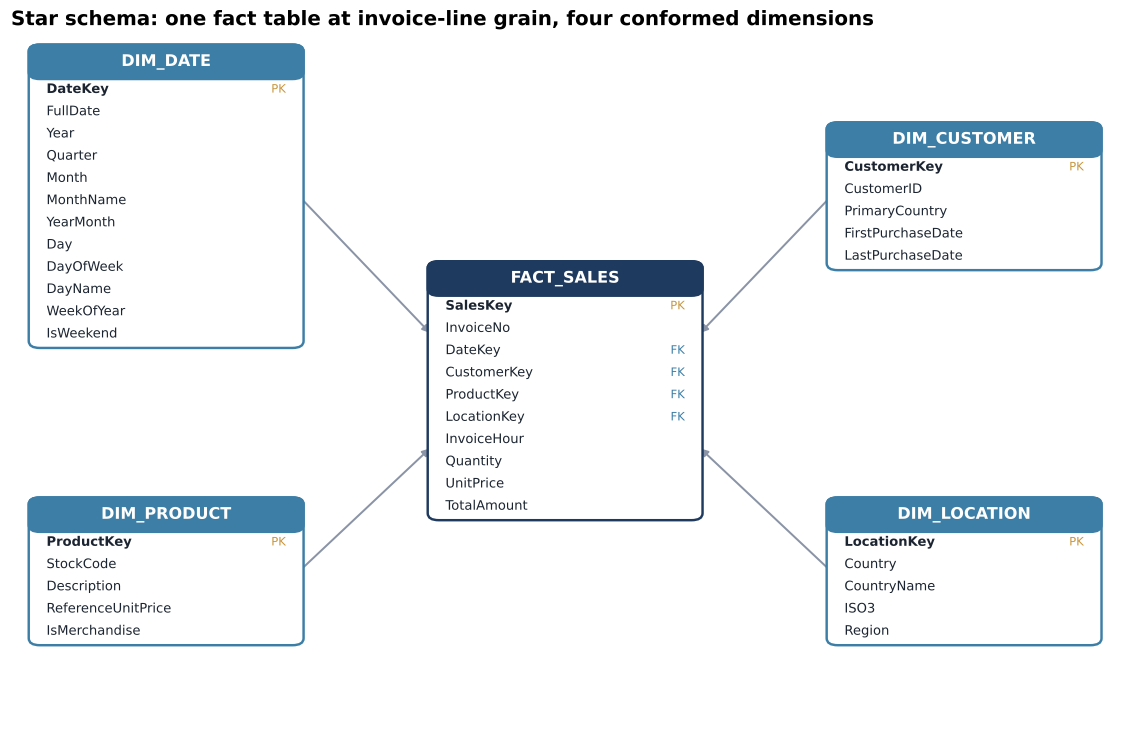

In [7]:
tables = {name: list(frame.columns) for name, frame in schema.items()}
tables = {k: tables[k] for k in ["fact_sales", "dim_date", "dim_customer", "dim_product", "dim_location"]}
keys = {
    "fact_sales": {"SalesKey": "PK", "DateKey": "FK", "CustomerKey": "FK", "ProductKey": "FK", "LocationKey": "FK"},
    "dim_date": {"DateKey": "PK"},
    "dim_customer": {"CustomerKey": "PK"},
    "dim_product": {"ProductKey": "PK"},
    "dim_location": {"LocationKey": "PK"},
}
fig = star_schema_diagram(tables, keys)
save_figure(fig, "02_star_schema")
plt.show()

### 2.1 Dimension previews

In [8]:
for name in ["dim_date", "dim_customer", "dim_product", "dim_location"]:
    display(Markdown(f"**{name}** ({len(schema[name]):,} rows)"))
    display(schema[name].head(5))

**dim_date** (739 rows)

,DateKey,FullDate,Year,Quarter,Month,MonthName,YearMonth,Day,DayOfWeek,DayName,WeekOfYear,IsWeekend
0,20091201,2009-12-01,2009,4,12,December,2009-12,1,2,Tuesday,49,False
1,20091202,2009-12-02,2009,4,12,December,2009-12,2,3,Wednesday,49,False
2,20091203,2009-12-03,2009,4,12,December,2009-12,3,4,Thursday,49,False
3,20091204,2009-12-04,2009,4,12,December,2009-12,4,5,Friday,49,False
4,20091205,2009-12-05,2009,4,12,December,2009-12,5,6,Saturday,49,True


**dim_customer** (5,878 rows)

,CustomerKey,CustomerID,PrimaryCountry,FirstPurchaseDate,LastPurchaseDate
0,1,12346,United Kingdom,2009-12-14,2011-01-18
1,2,12347,Iceland,2010-10-31,2011-12-07
2,3,12348,Finland,2010-09-27,2011-09-25
3,4,12349,Italy,2010-04-29,2011-11-21
4,5,12350,Norway,2011-02-02,2011-02-02


**dim_product** (4,631 rows)

,ProductKey,StockCode,Description,ReferenceUnitPrice,IsMerchandise
0,1,10002,INFLATABLE POLITICAL GLOBE,0.85,True
1,2,10080,GROOVY CACTUS INFLATABLE,0.39,True
2,3,10109,BENDY COLOUR PENCILS,0.42,True
3,4,10120,DOGGY RUBBER,0.21,True
4,5,10123C,HEARTS WRAPPING TAPE,0.65,True


**dim_location** (41 rows)

,LocationKey,Country,CountryName,ISO3,Region
0,1,Australia,Australia,AUS,Asia Pacific
1,2,Austria,Austria,AUT,Western Europe
2,3,Bahrain,Bahrain,BHR,Middle East & Africa
3,4,Belgium,Belgium,BEL,Western Europe
4,5,Brazil,Brazil,BRA,Americas


In [9]:
display(Markdown(f"**fact_sales** ({len(schema['fact_sales']):,} rows)"))
schema["fact_sales"].head()

**fact_sales** (779,425 rows)

,SalesKey,InvoiceNo,DateKey,CustomerKey,ProductKey,LocationKey,InvoiceHour,Quantity,UnitPrice,TotalAmount
0,1,489434,20091201,736,4010,39,7,12,6.95,83.40
1,2,489434,20091201,736,3327,39,7,12,6.75,81.00
2,3,489434,20091201,736,3329,39,7,12,6.75,81.00
3,4,489434,20091201,736,1254,39,7,48,2.10,100.80
4,5,489434,20091201,736,619,39,7,24,1.25,30.00


### 2.2 Referential integrity

In [10]:
integrity = check_referential_integrity(schema)
display(integrity)

revenue_source = df["TotalAmount"].sum()
revenue_fact = schema["fact_sales"]["TotalAmount"].sum()
print(f"Revenue in source: {revenue_source:,.2f}")
print(f"Revenue in fact table: {revenue_fact:,.2f}")
assert np.isclose(revenue_source, revenue_fact) and (integrity["Status"] == "PASS").all()
print("Fact table reconciles with the source and every foreign key resolves.")

,ForeignKey,References,OrphanRows,Status
0,fact_sales.DateKey,dim_date.DateKey,0,PASS
1,fact_sales.CustomerKey,dim_customer.CustomerKey,0,PASS
2,fact_sales.ProductKey,dim_product.ProductKey,0,PASS
3,fact_sales.LocationKey,dim_location.LocationKey,0,PASS


Revenue in source: 17,374,804.27
Revenue in fact table: 17,374,804.27
Fact table reconciles with the source and every foreign key resolves.


## 3. Physical warehouse in DuckDB

DuckDB is an embedded, columnar OLAP engine: it runs in-process, needs no server, and executes analytical SQL over
hundreds of thousands of rows in milliseconds. The DDL below is applied verbatim from the DDL script, then the
tables are loaded in dependency order and the indexes in the index script are created.

In [11]:
print(SQL_FILES["schema.sql"][:2400])

-- =============================================================================
-- Online Retail II - Star Schema (DuckDB dialect, ANSI-compatible)
-- Grain of the fact table: one row per invoice line.
-- Author: Sara Mohammad Zreigat
-- =============================================================================

-- -----------------------------------------------------------------------------
-- Dimension: calendar date (day grain)
-- -----------------------------------------------------------------------------
CREATE TABLE dim_date (
    DateKey        INTEGER      PRIMARY KEY,   -- YYYYMMDD smart key
    FullDate       DATE         NOT NULL,
    Year           SMALLINT     NOT NULL,
    Quarter        TINYINT      NOT NULL,
    Month          TINYINT      NOT NULL,
    MonthName      VARCHAR(12)  NOT NULL,
    YearMonth      VARCHAR(7)   NOT NULL,
    Day            TINYINT      NOT NULL,
    DayOfWeek      TINYINT      NOT NULL,      -- 1 = Monday ... 7 = Sunday
    DayName      

In [12]:
con = create_warehouse(schema)
con.execute(
    """
    SELECT table_name, estimated_size AS rows, column_count
    FROM duckdb_tables()
    ORDER BY table_name
    """
).df()

,table_name,rows,column_count
0,dim_customer,5878,5
1,dim_date,739,12
2,dim_location,41,5
3,dim_product,4631,5
4,fact_sales,779425,10


In [13]:
con.execute("SELECT index_name, table_name, sql FROM duckdb_indexes() ORDER BY table_name, index_name").df()

,index_name,table_name,sql
0,idx_dim_date_year_month,dim_date,CREATE INDEX idx_dim_date_year_month ON dim_da...
1,idx_dim_location_region,dim_location,CREATE INDEX idx_dim_location_region ON dim_lo...
2,idx_fact_sales_customer,fact_sales,CREATE INDEX idx_fact_sales_customer ON fact_s...
3,idx_fact_sales_date,fact_sales,CREATE INDEX idx_fact_sales_date ON fact_sales...
4,idx_fact_sales_invoice,fact_sales,CREATE INDEX idx_fact_sales_invoice ON fact_sa...
5,idx_fact_sales_location,fact_sales,CREATE INDEX idx_fact_sales_location ON fact_s...
6,idx_fact_sales_product,fact_sales,CREATE INDEX idx_fact_sales_product ON fact_sa...


## 4. Analytical queries

In [14]:
queries = load_named_queries()
query_results = {}
print(f"{len(queries)} named queries loaded from sql/analytical_queries.sql: {', '.join(queries)}")

7 named queries loaded from sql/analytical_queries.sql: revenue_by_country, monthly_sales_trend, top_products_by_revenue, repeat_customer_value, sales_by_weekday_hour, quarterly_rollup, customer_cohort_retention


### 4.1 Revenue by country and region

In [15]:
print(queries["revenue_by_country"])
query_results["revenue_by_country"], ms = run_query(con, queries["revenue_by_country"])
print(f"\nExecuted in {ms:.1f} ms")
query_results["revenue_by_country"].head(10)

-- Revenue, volume and order metrics by country and region.
SELECT
    l.CountryName                              AS Country,
    l.Region,
    COUNT(DISTINCT f.InvoiceNo)                AS Orders,
    COUNT(DISTINCT f.CustomerKey)              AS Customers,
    CAST(SUM(f.Quantity) AS BIGINT)            AS UnitsSold,
    ROUND(SUM(f.TotalAmount), 2)               AS Revenue,
    ROUND(SUM(f.TotalAmount) / COUNT(DISTINCT f.InvoiceNo), 2) AS AvgOrderValue,
    ROUND(100.0 * SUM(f.TotalAmount) / SUM(SUM(f.TotalAmount)) OVER (), 2) AS RevenueSharePct
FROM fact_sales f
JOIN dim_location l ON f.LocationKey = l.LocationKey
GROUP BY l.CountryName, l.Region
ORDER BY Revenue DESC

Executed in 53.9 ms


,Country,Region,Orders,Customers,UnitsSold,Revenue,AvgOrderValue,RevenueSharePct
0,United Kingdom,United Kingdom,33541,5350,8532411,"14,389,234.92",429.00,82.82
1,Ireland,Western Europe,567,5,318021,"616,570.54","1,087.43",3.55
2,Netherlands,Western Europe,228,22,383879,"554,038.09","2,429.99",3.19
3,Germany,Western Europe,789,107,225154,"425,019.71",538.68,2.45
4,France,Western Europe,614,95,270288,"348,768.96",568.03,2.01
5,Australia,Asia Pacific,95,15,103759,"169,283.46","1,781.93",0.97
6,Spain,Southern Europe,154,41,50307,"108,332.49",703.46,0.62
7,Switzerland,Western Europe,90,22,52227,"100,061.94","1,111.80",0.58
8,Sweden,Northern Europe,104,19,88495,"91,515.82",879.96,0.53
9,Denmark,Northern Europe,43,12,237471,"68,580.69","1,594.90",0.39


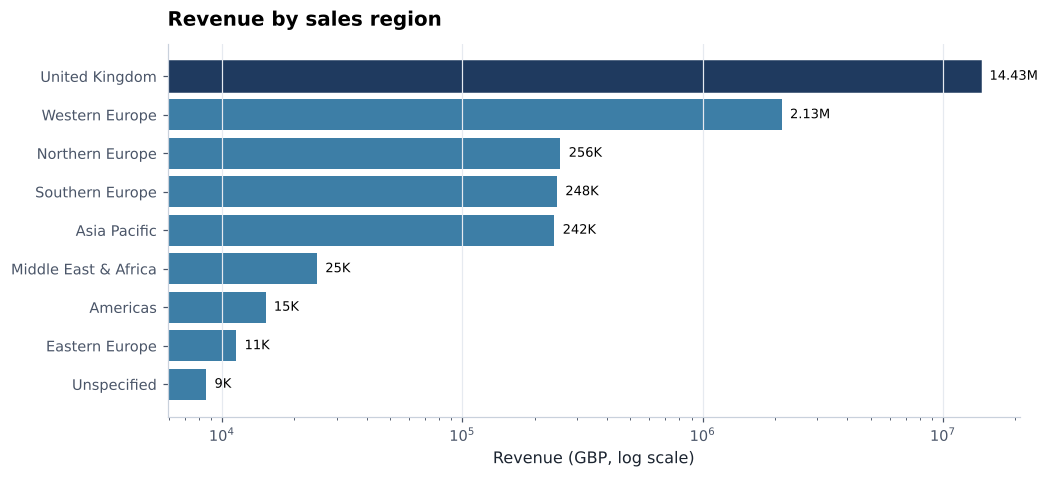

In [16]:
by_region = query_results["revenue_by_country"].groupby("Region")["Revenue"].sum().sort_values()
fig, ax = plt.subplots(figsize=(10, 4.4))
bars = ax.barh(by_region.index, by_region.values, color=PALETTE["secondary"])
bars[-1].set_color(PALETTE["primary"])
ax.set_xscale("log")
ax.set_xlabel("Revenue (GBP, log scale)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("Revenue by sales region")
for y, value in enumerate(by_region.values):
    ax.text(value, y, f"  {value / 1e6:.2f}M" if value >= 1e6 else f"  {value / 1e3:.0f}K", va="center", fontsize=8.5)
save_figure(fig, "02_revenue_by_region")
plt.show()

### 4.2 Monthly sales trend with growth rates

In [17]:
print(queries["monthly_sales_trend"])
query_results["monthly_sales_trend"], ms = run_query(con, queries["monthly_sales_trend"])
print(f"\nExecuted in {ms:.1f} ms")
query_results["monthly_sales_trend"]

-- Monthly revenue with month-over-month and year-over-year growth.
WITH monthly AS (
    SELECT
        d.Year,
        d.Month,
        d.YearMonth,
        COUNT(DISTINCT f.InvoiceNo)   AS Orders,
        COUNT(DISTINCT f.CustomerKey) AS ActiveCustomers,
        SUM(f.TotalAmount)            AS Revenue
    FROM fact_sales f
    JOIN dim_date d ON f.DateKey = d.DateKey
    GROUP BY d.Year, d.Month, d.YearMonth
)
SELECT
    YearMonth,
    Year,
    Month,
    Orders,
    ActiveCustomers,
    ROUND(Revenue, 2) AS Revenue,
    ROUND(100.0 * (Revenue / LAG(Revenue) OVER (ORDER BY Year, Month) - 1), 2)  AS MoMGrowthPct,
    ROUND(100.0 * (Revenue / LAG(Revenue, 12) OVER (ORDER BY Year, Month) - 1), 2) AS YoYGrowthPct
FROM monthly
ORDER BY Year, Month

Executed in 53.0 ms


,YearMonth,Year,Month,Orders,ActiveCustomers,Revenue,MoMGrowthPct,YoYGrowthPct
0,2009-12,2009,12,1512,955,"683,504.01",NaN,NaN
1,2010-01,2010,1,1011,720,"555,802.67",-18.68,NaN
2,2010-02,2010,2,1104,772,"504,558.96",-9.22,NaN
3,2010-03,2010,3,1524,1057,"696,978.47",38.14,NaN
4,2010-04,2010,4,1329,942,"591,982.00",-15.06,NaN
5,2010-05,2010,5,1377,966,"597,833.38",0.99,NaN
6,2010-06,2010,6,1497,1041,"636,371.13",6.45,NaN
7,2010-07,2010,7,1381,928,"589,736.17",-7.33,NaN
8,2010-08,2010,8,1293,911,"602,224.60",2.12,NaN
9,2010-09,2010,9,1689,1145,"829,013.95",37.66,NaN


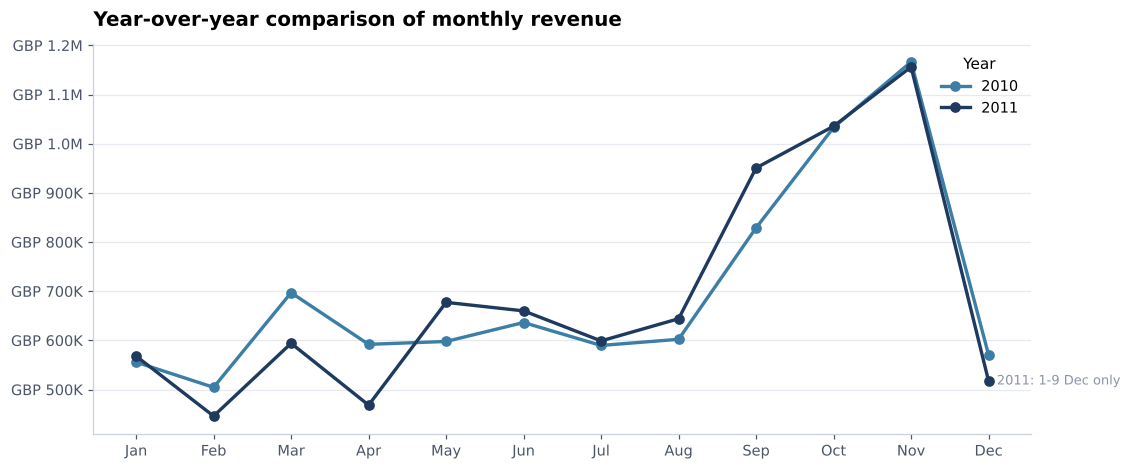

In [18]:
trend = query_results["monthly_sales_trend"].copy()
fig, ax = plt.subplots(figsize=(11, 4.6))
for year, color in zip([2010, 2011], [PALETTE["secondary"], PALETTE["primary"]]):
    subset = trend[trend["Year"] == year]
    ax.plot(subset["Month"], subset["Revenue"], marker="o", linewidth=2.2, color=color, label=str(year))
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.yaxis.set_major_formatter(currency_formatter())
ax.set_title("Year-over-year comparison of monthly revenue")
ax.legend(title="Year")
ax.text(12, trend.iloc[-1]["Revenue"], "  2011: 1-9 Dec only", fontsize=8.5, color=PALETTE["neutral"], va="center")
save_figure(fig, "02_yoy_monthly_revenue")
plt.show()

### 4.3 Top products by revenue

In [19]:
print(queries["top_products_by_revenue"])
query_results["top_products_by_revenue"], ms = run_query(con, queries["top_products_by_revenue"])
print(f"\nExecuted in {ms:.1f} ms")
query_results["top_products_by_revenue"]

-- Ten highest-revenue merchandise products.
SELECT
    p.StockCode,
    p.Description,
    CAST(SUM(f.Quantity) AS BIGINT)      AS UnitsSold,
    COUNT(DISTINCT f.InvoiceNo)          AS Orders,
    ROUND(SUM(f.TotalAmount), 2)         AS Revenue,
    ROUND(SUM(f.TotalAmount) / SUM(f.Quantity), 2) AS AvgSellingPrice
FROM fact_sales f
JOIN dim_product p ON f.ProductKey = p.ProductKey
WHERE p.IsMerchandise
GROUP BY p.StockCode, p.Description
ORDER BY Revenue DESC
LIMIT 10

Executed in 169.7 ms


,StockCode,Description,UnitsSold,Orders,Revenue,AvgSellingPrice
0,22423,REGENCY CAKESTAND 3 TIER,24124,3317,"277,656.25",11.51
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,91814,4895,"247,203.36",2.69
2,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,1,"168,469.60",2.08
3,85099B,JUMBO BAG RED RETROSPOT,93436,3260,"167,920.64",1.80
4,84879,ASSORTED COLOUR BIRD ORNAMENT,78234,2652,"124,351.86",1.59
5,47566,PARTY BUNTING,23460,2077,"103,283.38",4.40
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,77916,195,"81,416.73",1.04
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,28380,1691,"76,598.18",2.70
8,79321,CHILLI LIGHTS,14843,922,"69,084.30",4.65
9,22386,JUMBO BAG PINK POLKADOT,37338,1767,"67,769.76",1.82


### 4.4 Repeat-customer value

In [20]:
print(queries["repeat_customer_value"])
query_results["repeat_customer_value"], ms = run_query(con, queries["repeat_customer_value"])
repeat = query_results["repeat_customer_value"]
share = repeat["LifetimeRevenue"].sum() / df["TotalAmount"].sum()
print(f"\nExecuted in {ms:.1f} ms")
print(f"{len(repeat):,} customers with more than five orders generate {share:.1%} of total revenue.")
repeat.head(10)

-- Customers with more than five orders, ranked by lifetime revenue.
SELECT
    c.CustomerID,
    c.PrimaryCountry,
    COUNT(DISTINCT f.InvoiceNo)                AS Orders,
    CAST(SUM(f.Quantity) AS BIGINT)            AS UnitsPurchased,
    ROUND(SUM(f.TotalAmount), 2)               AS LifetimeRevenue,
    ROUND(SUM(f.TotalAmount) / COUNT(DISTINCT f.InvoiceNo), 2) AS AvgOrderValue,
    c.FirstPurchaseDate,
    c.LastPurchaseDate
FROM fact_sales f
JOIN dim_customer c ON f.CustomerKey = c.CustomerKey
GROUP BY c.CustomerID, c.PrimaryCountry, c.FirstPurchaseDate, c.LastPurchaseDate
HAVING COUNT(DISTINCT f.InvoiceNo) > 5
ORDER BY LifetimeRevenue DESC



Executed in 43.6 ms
1,801 customers with more than five orders generate 80.1% of total revenue.


,CustomerID,PrimaryCountry,Orders,UnitsPurchased,LifetimeRevenue,AvgOrderValue,FirstPurchaseDate,LastPurchaseDate
0,18102,United Kingdom,145,181645,"580,987.04","4,006.81",2009-12-01,2011-12-09
1,14646,Netherlands,151,367193,"528,602.52","3,500.68",2009-12-02,2011-12-08
2,14156,EIRE,156,164325,"313,437.62","2,009.22",2009-12-01,2011-11-30
3,14911,EIRE,398,147972,"291,420.81",732.21,2009-12-01,2011-12-08
4,17450,United Kingdom,51,83914,"244,784.25","4,799.69",2010-09-27,2011-12-01
5,13694,United Kingdom,143,188201,"195,640.69","1,368.12",2009-12-04,2011-12-06
6,17511,United Kingdom,60,117174,"172,132.87","2,868.88",2009-12-02,2011-12-07
7,16684,United Kingdom,55,104810,"147,142.77","2,675.32",2009-12-07,2011-12-05
8,12415,Australia,28,91447,"144,458.37","5,159.23",2010-06-30,2011-11-15
9,15061,United Kingdom,127,74280,"126,389.02",995.19,2009-12-01,2011-12-06


### 4.5 Weekday and hour activity

In [21]:
query_results["sales_by_weekday_hour"], ms = run_query(con, queries["sales_by_weekday_hour"])
print(f"Executed in {ms:.1f} ms")
pivot = query_results["sales_by_weekday_hour"].pivot_table(index="DayName", columns="Hour", values="Orders", fill_value=0)
pivot = pivot.reindex([d for d in ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"] if d in pivot.index])
pivot

Executed in 59.1 ms


Hour,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
DayName,,,,,,,,,,,,,,,
Monday,0.00,14.00,165.00,452.00,669.00,684.00,965.00,877.00,735.00,654.00,381.00,147.00,12.00,0.00,0.00
Tuesday,0.00,17.00,200.00,583.00,786.00,791.00,"1,071.00",992.00,754.00,652.00,422.00,256.00,71.00,30.00,2.00
Wednesday,0.00,11.00,201.00,531.00,813.00,792.00,"1,159.00","1,002.00",857.00,683.00,448.00,149.00,0.00,2.00,1.00
Thursday,1.00,22.00,210.00,519.00,817.00,766.00,"1,093.00",969.00,851.00,786.00,593.00,487.00,330.00,283.00,47.00
Friday,0.00,12.00,203.00,457.00,754.00,734.00,906.00,745.00,696.00,508.00,241.00,119.00,2.00,9.00,1.00
Saturday,0.00,0.00,0.00,0.00,6.00,1.00,6.00,7.00,3.00,5.00,2.00,0.00,0.00,0.00,0.00
Sunday,0.00,0.00,0.00,6.00,519.00,841.00,970.00,826.00,663.00,704.00,219.00,0.00,0.00,0.00,0.00


### 4.6 Quarterly roll-up

In [22]:
print(queries["quarterly_rollup"])
query_results["quarterly_rollup"], ms = run_query(con, queries["quarterly_rollup"])
print(f"\nExecuted in {ms:.1f} ms")
query_results["quarterly_rollup"]

-- ROLLUP across year and quarter with subtotals and a grand total.
SELECT
    COALESCE(CAST(d.Year AS VARCHAR), 'All years')        AS Year,
    COALESCE(CAST(d.Quarter AS VARCHAR), 'All quarters') AS Quarter,
    COUNT(DISTINCT f.InvoiceNo)                           AS Orders,
    ROUND(SUM(f.TotalAmount), 2)                          AS Revenue
FROM fact_sales f
JOIN dim_date d ON f.DateKey = d.DateKey
GROUP BY ROLLUP (d.Year, d.Quarter)
ORDER BY d.Year NULLS LAST, d.Quarter NULLS LAST



Executed in 45.4 ms


,Year,Quarter,Orders,Revenue
0,2009,4,1512,"683,504.01"
1,2009,All quarters,1512,"683,504.01"
2,2010,1,3639,"1,757,340.10"
3,2010,2,4203,"1,826,186.51"
4,2010,3,4363,"2,020,974.72"
5,2010,4,6120,"2,769,994.76"
6,2010,All quarters,18325,"8,374,496.09"
7,2011,1,3305,"1,608,267.99"
8,2011,2,4097,"1,805,775.53"
9,2011,3,4366,"2,193,704.14"


### 4.7 Cohort retention

Executed in 26.9 ms


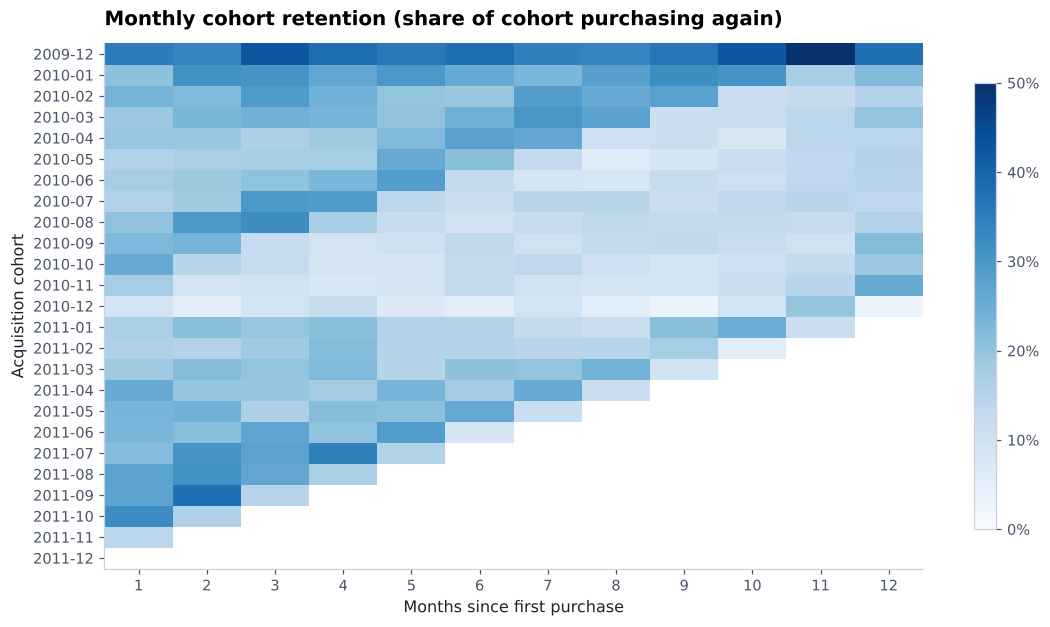

MonthsSinceFirstPurchase,0,1,2,3,4,5,6
Cohort,,,,,,,
2009-12,100%,35%,33%,43%,38%,36%,38%
2010-01,100%,21%,31%,31%,26%,30%,26%
2010-02,100%,24%,22%,29%,25%,20%,19%
2010-03,100%,19%,23%,24%,23%,20%,25%
2010-04,100%,19%,19%,16%,18%,22%,28%
2010-05,100%,16%,17%,17%,18%,26%,21%
2010-06,100%,17%,19%,20%,23%,29%,13%
2010-07,100%,16%,18%,30%,29%,14%,11%


In [23]:
query_results["customer_cohort_retention"], ms = run_query(con, queries["customer_cohort_retention"])
print(f"Executed in {ms:.1f} ms")
cohorts = query_results["customer_cohort_retention"].pivot(
    index="Cohort", columns="MonthsSinceFirstPurchase", values="ActiveCustomers"
)
retention = cohorts.div(cohorts[0], axis=0)

fig, ax = plt.subplots(figsize=(12, 6.2))
image = ax.imshow(retention.iloc[:, 1:13].values, aspect="auto", cmap="Blues", vmin=0, vmax=0.5)
ax.set_xticks(range(12), [str(i) for i in range(1, 13)])
ax.set_yticks(range(len(retention)), retention.index)
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Acquisition cohort")
ax.grid(False)
ax.set_title("Monthly cohort retention (share of cohort purchasing again)")
fig.colorbar(image, ax=ax, format=lambda x, _: f"{x:.0%}", shrink=0.85)
save_figure(fig, "02_cohort_retention")
plt.show()

retention.iloc[:8, :7].map(lambda v: f"{v:.0%}" if pd.notna(v) else "")

The December 2009 cohort is exceptional: it contains every customer already active when the data starts, and about a
third of them buy again in any later month. Cohorts acquired afterwards retain at markedly lower rates, which makes
early-life nurturing a clear opportunity (see the *Promising* segment in notebook 03).

## 5. Query performance

In [24]:
benchmarks = benchmark_queries(con, queries)
benchmarks

,Query,ResultRows,MedianMs,MinMs
0,revenue_by_country,41,45.56,43.62
1,monthly_sales_trend,25,40.51,38.22
2,top_products_by_revenue,10,166.79,141.74
3,repeat_customer_value,1801,41.88,35.68
4,sales_by_weekday_hour,83,37.37,29.49
5,quarterly_rollup,13,41.09,38.62
6,customer_cohort_retention,325,36.43,34.54


In [25]:
explain = con.execute("EXPLAIN " + queries["revenue_by_country"]).df()
print(explain.iloc[0, 1][:1800])

┌───────────────────────────┐
│          ORDER_BY         │
│    ────────────────────   │
│ round(sum(f.TotalAmount), │
│           2) DESC         │
└─────────────┬─────────────┘
┌─────────────┴─────────────┐
│         PROJECTION        │
│    ────────────────────   │
│          Country          │
│           Region          │
│           Orders          │
│         Customers         │
│         UnitsSold         │
│          Revenue          │
│       AvgOrderValue       │
│      RevenueSharePct      │
│                           │
│       ~759,832 rows       │
└─────────────┬─────────────┘
┌─────────────┴─────────────┐
│         PROJECTION        │
│    ────────────────────   │
│             #0            │
│             #1            │
│             #2            │
│             #3            │
│             #4            │
│             #5            │
│             #6            │
│                           │
│       ~759,832 rows       │
└─────────────┬─────────────┘
┌─────────

Every query completes in well under a second on the full 779,425-row fact table. DuckDB answers these aggregations
with vectorised columnar scans and hash joins; the ART indexes created in the index script serve selective point
lookups (for example a single customer or invoice) and enforce key uniqueness.

## 6. Persist stage outputs

In [26]:
persist_warehouse(summary, integrity, query_results, benchmarks)
con.close()
print("Query results saved to artifacts/warehouse/")

Query results saved to artifacts/warehouse/


## 7. Key findings

* The warehouse contains **1 fact table (779,425 rows) and 4 dimensions** (739 dates, 5,878 customers,
  4,631 products, 41 locations); all foreign keys resolve and revenue reconciles to the source.
* The United Kingdom accounts for 82.8% of revenue; Western Europe is the largest international region.
* November is the peak month in both full years, and 2011 tracked 2010 closely, indicating a stable but
  flat business year on year.
* **1,801 customers with more than five orders (31% of the base) generate 80.1% of revenue**, confirming that retention
  of repeat buyers is the main commercial lever.
* Cohort analysis shows low month-on-month retention for newly acquired customers.

Next: notebook 03 applies unsupervised data mining.